# **Анализ данных маркетплейса Olist**

Мурад Абакаров

В этой работе рассмотрим данные бразильского маркетплейса Olist. Сначала изучим таблицы и подготовим данные, затем посчитаем основные метрики и посмотрим, как часто покупатели возвращаются.

Отдельно разберем воронку интернет-магазина и проведем несколько симуляций A/A- и A/B-тестов.

<u>Данные для работы</u>

- [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): около 100 тыс. заказов за 2016–2018 годы. В датасете есть таблицы покупателей, продавцов, заказов, товаров, платежей и отзывов.

- Для анализа воронки используется отдельный файл синтетический `funnel_events.csv` с событиями 6 000 пользователей за январь–март 2026 года. Для запуска его нужно положить рядом с ноутбуком.

- В разделе со статистическими тестами используются *синтетические данные*, сгенерированные с помощью NumPy.

В работе используются Python, pandas, NumPy, Matplotlib, statsmodels и SciPy.

<a id="contents" name="contents"></a>

### Содержание

1. [Загрузка библиотек и данных](#scrollTo=bllONMckdd2E)
2. [Первичный анализ данных](#scrollTo=g_NfQc5Udd2G)
3. [Аналитика средствами pandas](#scrollTo=AZu7_Bu9dd2S)
4. [Продуктовые метрики и когортный анализ](#scrollTo=0kJGKCXIdd2W)
5. [Анализ воронки](#scrollTo=GR5LaRfUdd2Z)
6. [A/B-тестирование bootstrap и A/A-тестирование](#scrollTo=yAJFsQkkdd2c)
7. [Общие выводы](#scrollTo=gcAxh404dd2g)

<a id="part1" name="part1"></a>

## **1. Загрузка библиотек и данных**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

Скачаем датасет с помощью `kagglehub` и загрузим восемь таблиц в отдельные датафреймы.

In [ ]:

# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
import os
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
os.listdir(path)





Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.


['olist_customers_dataset.csv',
 'olist_sellers_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_products_dataset.csv',
 'olist_geolocation_dataset.csv',
 'product_category_name_translation.csv',
 'olist_orders_dataset.csv',
 'olist_order_payments_dataset.csv']

In [ ]:
import pandas as pd

In [ ]:
customers = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
sellers = pd.read_csv(os.path.join(path,'olist_sellers_dataset.csv'))
orders = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
order_items = pd.read_csv(os.path.join(path,  'olist_order_items_dataset.csv'))
order_payment = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv' ))
product_category_name_translation = pd.read_csv(os.path.join(path,'product_category_name_translation.csv'))
order_reviews = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))
products = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))

In [ ]:
all_datas = [customers, sellers, orders, order_items, order_payment, product_category_name_translation, order_reviews ]

<a id="part2" name="part2"></a>

## **2. Первичный анализ данных**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

Для каждой таблицы посмотрим размер, первые и последние строки, типы данных, пропуски и дубликаты. Также определим, чему соответствует одна строка, чтобы правильно объединять таблицы и считать метрики.

### 2.1. Покупатели — таблица `customers`

In [ ]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
customers.tail()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS
99440,274fa6071e5e17fe303b9748641082c8,84732c5050c01db9b23e19ba39899398,6703,cotia,SP


In [ ]:
customers.sample(5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
25616,08a0a61f98f22952682f7e463ef2d43e,478098554da8910383d47ec3788a9905,19912,ourinhos,SP
85156,74a5c783c269854f424a5ee0eecda16b,c7635497d15ff3d2935040331df7f001,38140,prata,MG
56664,80a4c819314e5ff01e66ba8780857b4e,176c21456fab655afee57b3ea9799f47,14750,pitangueiras,SP
48412,8434c341761f602a26ca1f2b6ee6cee1,40e57165f0bb1b528de29eaecb7fa245,78250,pontes e lacerda,MT
51142,1a0e67acb719bb00bcee2e586ff3a2d8,8adce5effe5d3b90e0ff802544d649ea,22710,rio de janeiro,RJ


In [ ]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [ ]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [ ]:
customers.describe(include='all')

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,274fa6071e5e17fe303b9748641082c8,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [ ]:
customers.isna().sum()

,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


In [ ]:
customers.isna().mean().sort_values(ascending=False)

,0
customer_id,0.0
customer_unique_id,0.0
customer_zip_code_prefix,0.0
customer_city,0.0
customer_state,0.0


In [ ]:
customers.duplicated().sum()

np.int64(0)

In [ ]:
customers.nunique()

,0
customer_id,99441
customer_unique_id,96096
customer_zip_code_prefix,14994
customer_city,4119
customer_state,27


In [ ]:
customers.dtypes

,0
customer_id,object
customer_unique_id,object
customer_zip_code_prefix,int64
customer_city,object
customer_state,object


In [ ]:
if len(customers) == customers['customer_id'].nunique():
  print('Значит, одна строка соответствует одному уникальному customer_id')
else:
  print('Нужно разобраться, что описывает одна строка')

Значит, одна строка соответствует одному уникальному customer_id


В таблице 99 441 строка, пропусков и дубликатов нет. Каждая строка соответствует одному `customer_id`.

При этом уникальных `customer_unique_id` только 96 096. Разница связана с тем, что `customer_id` присваивается при каждом заказе, а `customer_unique_id` позволяет определить одного и того же покупателя. Поэтому дальше будем считать клиентов по **`customer_unique_id`**. Покупатели представлены в 27 штатах и 4 119 городах.

### 2.2. Таблица `sellers`: продавцы

In [ ]:
sellers.shape

(3095, 4)

In [ ]:
sellers.head()


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
sellers.sample(5)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
571,34d1ca11b242c0fee2c834ae8d788566,36415,congonhas,MG
3030,5de1c80811ce7007f62f00d971236c09,88063,florianopolis,SC
2494,08d1c9478fb0d7d7fcac9c0da4e82fc7,31110,belo horizonte,MG
1530,02b72cdeb9cfcc429f1af6f4e3f3b737,14940,ibitinga,SP
2690,bec568278124768c474ee90971ca94d1,3553,sao paulo,SP


In [ ]:
sellers.tail()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS
3094,9e25199f6ef7e7c347120ff175652c3b,12051,taubate,SP


In [ ]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [ ]:
sellers.columns

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='object')

In [ ]:
sellers.describe(include='all')

,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.000000,3095,3095
unique,3095,NaN,611,23
top,9e25199f6ef7e7c347120ff175652c3b,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.059451,NaN,NaN
std,NaN,32713.453830,NaN,NaN
min,NaN,1001.000000,NaN,NaN
25%,NaN,7093.500000,NaN,NaN
50%,NaN,14940.000000,NaN,NaN
75%,NaN,64552.500000,NaN,NaN


In [ ]:
sellers.isna().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [ ]:
sellers.isna().mean().sort_values(ascending=False)

,0
seller_id,0.0
seller_zip_code_prefix,0.0
seller_city,0.0
seller_state,0.0


In [ ]:
sellers.dtypes

,0
seller_id,object
seller_zip_code_prefix,int64
seller_city,object
seller_state,object


In [ ]:
sellers.duplicated().sum()

np.int64(0)

In [ ]:
sellers.duplicated().mean()

np.float64(0.0)

In [ ]:
sellers.seller_state.unique() # уникальные значения, которые принимает колонка

array(['SP', 'RJ', 'PE', 'PR', 'GO', 'SC', 'BA', 'DF', 'RS', 'MG', 'RN',
       'MT', 'CE', 'PB', 'AC', 'ES', 'RO', 'PI', 'MS', 'SE', 'MA', 'AM',
       'PA'], dtype=object)

In [ ]:
sellers['seller_state'].value_counts() # сколько раз встречается каждое значение колонки

,count
seller_state,
SP,1849
PR,349
MG,244
SC,190
RJ,171
RS,129
GO,40
DF,30
ES,23


In [ ]:
len(sellers) == sellers.nunique()

,0
seller_id,True
seller_zip_code_prefix,False
seller_city,False
seller_state,False


In [ ]:
if len(sellers) == sellers['seller_id'].nunique():
  print('Значит, одна строка соответствует одному уникальному seller_id')
else:
  print('Нужно разобраться, что описывает одна строка')


Значит, одна строка соответствует одному уникальному seller_id


In [ ]:
sellers['seller_id'].is_unique

True

In [ ]:
sellers['seller_state'].is_unique


False

В таблице 3 095 продавцов, пропусков и дубликатов нет. Значения `seller_id` уникальны, то есть одна строка соответствует одному продавцу.

Больше всего продавцов находится в штате SP: 1 849, или около 60%. Далее идут PR (349) и MG (244).

### 2.3. Таблица `orders`: заказы

In [ ]:
orders.shape

(99441, 8)

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.tail()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


In [ ]:
orders.sample(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
22927,4bfcba9e084f46c8e3cb49b0fa6e6159,de832e8dbb1f588a47013e53feaa67cc,delivered,2017-05-29 14:06:33,2017-05-29 14:25:14,2017-05-30 09:25:02,2017-06-01 15:34:09,2017-06-09 00:00:00
5603,b49fb5d1cf86975cf5a295431c278a33,919898139ad85605b36f05302f908a95,delivered,2018-06-11 18:18:36,2018-06-12 18:46:06,2018-06-15 14:27:00,2018-06-20 15:45:20,2018-06-28 00:00:00
36974,16aaefde5d48ac55cb13be6353f9d415,c616dbff41c008fb0d5f5e7bb8e742ba,delivered,2017-03-31 19:14:54,2017-03-31 19:25:07,2017-04-03 14:55:06,2017-04-07 11:52:11,2017-04-25 00:00:00


In [ ]:
orders.dtypes


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object


In [ ]:
orders['order_id'].is_unique # проверка гранулярности: одна строка = один уникальный заказ

True

In [ ]:
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


#### Приведение дат к нужному типу

Колонки начиная с `order_purchase_timestamp` содержат даты, но имеют тип `object`. Переведем их в `datetime`, чтобы дальше работать с датами и рассчитывать временные интервалы.

In [ ]:
date_cols = list(orders.columns)[3:]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)


In [ ]:
orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
orders.nunique()

,0
order_id,99441
customer_id,99441
order_status,8
order_purchase_timestamp,98875
order_approved_at,90733
order_delivered_carrier_date,81018
order_delivered_customer_date,95664
order_estimated_delivery_date,459


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [ ]:
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
orders.isna().mean().mul(100).sort_values(ascending=False)

,0
order_delivered_customer_date,2.981668
order_delivered_carrier_date,1.793023
order_approved_at,0.160899
order_id,0.000000
order_purchase_timestamp,0.000000
order_status,0.000000
customer_id,0.000000
order_estimated_delivery_date,0.000000


In [ ]:
orders.duplicated().sum()

np.int64(0)

In [ ]:
orders.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,NaN,NaN,NaN,NaN,NaN
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,NaN,NaN,NaN,NaN,NaN
freq,1,1,96478,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2017-12-31 08:43:12.776581120,2017-12-31 18:35:24.098800128,2018-01-04 21:49:48.138278656,2018-01-14 12:09:19.035542272,2018-01-24 03:08:37.730111232
min,NaN,NaN,NaN,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,NaN,NaN,NaN,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.249999872,2017-09-25 22:07:22.249999872,2017-10-03 00:00:00
50%,NaN,NaN,NaN,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00
75%,NaN,NaN,NaN,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.249999872,2018-05-25 00:00:00
max,NaN,NaN,NaN,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [ ]:
orders['order_purchase_timestamp'].dt.year
# orders['order_purchase_timestamp'].dt.month
orders['order_purchase_timestamp'].dt.day
orders['order_purchase_timestamp'].dt.dayofweek
# orders['order_purchase_timestamp'].dt.day_name()
# orders[date_cols].apply(lambda x: x.dt.day_name())


,order_purchase_timestamp
0,0
1,1
2,2
3,5
4,1
...,...
99436,3
99437,1
99438,6
99439,0


В таблице 99 441 заказ, `order_id` уникален. Около 97% заказов имеют статус `delivered`, доля отмененных заказов составляет 0,6%.

Пропуски есть в `order_delivered_customer_date` (2,98%), `order_delivered_carrier_date` (1,79%) и `order_approved_at` (0,16%). Они могут быть связаны со статусом заказа: например, у недоставленного заказа нет даты доставки. Поэтому не будем удалять строки только из-за этих пропусков.

### 2.4. Таблица `order_items`: позиции в заказе

In [ ]:
order_items.shape

(112650, 7)

In [ ]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
order_items.tail()


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72
112649,fffe41c64501cc87c801fd61db3f6244,1,350688d9dc1e75ff97be326363655e01,f7ccf836d21b2fb1de37564105216cc1,2018-06-12 17:10:13,43.00,12.79


In [ ]:
order_items.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
33993,4ceb9336411700f9568db2ef11bda594,2,9abb00920aae319ef9eba674b7d2e6ff,1771297ac436903d1dd6b0e9279aa505,2017-01-23 22:41:52,40.00,14.52
63554,911c0c489bf4354f38fc64491075e8ba,1,22f590c457402e4971c9c2090d34983d,921323538c9f1c4e816f2720eac02bea,2018-06-18 17:12:59,119.90,20.03
104633,edb14cad806f8ea19a08ed06c26726a2,1,9b0ad21bbd4384f9ebc28a688e1e81cd,128639473a139ac0f3e5f5ade55873a5,2018-02-13 07:55:23,18.90,12.48
3290,0764f8b9a45b0305b75e1bbd614ffaaa,1,61a53738adc5c0e8d243553320f9ba1c,7c67e1448b00f6e969d365cea6b010ab,2017-09-27 21:10:10,89.97,21.28
23895,367085f34fdfc417d0087dfeab08ad73,1,dbd55362ec13c706503b1c71a5068a1a,e24fc9fcd865784fb25705606fe3dfe7,2017-09-21 18:35:25,102.00,36.03


In [ ]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [ ]:
order_items.dtypes

,0
order_id,object
order_item_id,int64
product_id,object
seller_id,object
shipping_limit_date,object
price,float64
freight_value,float64


In [ ]:
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])


In [ ]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [ ]:
order_items.dtypes

,0
order_id,object
order_item_id,int64
product_id,object
seller_id,object
shipping_limit_date,datetime64[ns]
price,float64
freight_value,float64


In [ ]:
order_items.describe(include='all', percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.000000,112650,112650,112650,112650.000000,112650.000000
unique,98666,NaN,32951,3095,NaN,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,NaN,NaN,NaN
freq,21,NaN,527,2033,NaN,NaN,NaN
mean,NaN,1.197834,NaN,NaN,2018-01-07 15:36:52.192685312,120.653739,19.990320
min,NaN,1.000000,NaN,NaN,2016-09-19 00:15:34,0.850000,0.000000
1%,NaN,1.000000,NaN,NaN,2017-02-02 23:56:31.560000,9.990000,4.419800
5%,NaN,1.000000,NaN,NaN,2017-03-31 15:12:10.250000128,17.000000,7.780000
25%,NaN,1.000000,NaN,NaN,2017-09-20 20:57:27.500000,39.900000,13.080000
50%,NaN,1.000000,NaN,NaN,2018-01-26 13:59:35,74.990000,16.260000


In [ ]:
order_items['shipping_limit_date'].dt.year

,shipping_limit_date
0,2017
1,2017
2,2018
3,2018
4,2017
...,...
112645,2018
112646,2018
112647,2017
112648,2017


In [ ]:
order_items.isna().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [ ]:
order_items.isna().mean()

,0
order_id,0.0
order_item_id,0.0
product_id,0.0
seller_id,0.0
shipping_limit_date,0.0
price,0.0
freight_value,0.0


In [ ]:
order_items.duplicated().sum()

np.int64(0)

In [ ]:
order_items.nunique()

,0
order_id,98666
order_item_id,21
product_id,32951
seller_id,3095
shipping_limit_date,93318
price,5968
freight_value,6999


В таблице 112 650 строк и 98 666 заказов. Одна строка соответствует позиции товара в заказе, которую определяет пара `order_id` и `order_item_id`. В одном заказе может быть несколько позиций, максимум — 21. Пропусков и дубликатов нет. Колонка `shipping_limit_date` приведена к типу `datetime`.

### 2.5. Таблица `order_payment`: платежи

In [ ]:
order_payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
order_payment.shape

(103886, 5)

In [ ]:
order_payment.tail()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54
103885,28bbae6599b09d39ca406b747b6632b1,1,boleto,1,191.58


In [ ]:
order_payment.sample(5)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
35556,d8f560d2563965001d1f853e74c82b0c,1,boleto,1,91.07
18934,c4eb6bb6cce4739be64f37565afd5436,1,credit_card,7,78.70
60899,65b8cbd6d0ad97befea844cc40817ccb,1,credit_card,3,79.19
103798,4f259869d5c650af6f847b027032515b,1,voucher,1,176.56
4950,600c05aa649cdbeaaf763a60cd0a12cf,1,credit_card,1,52.68


In [ ]:
order_payment.columns


Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

In [ ]:
order_payment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
order_payment.dtypes

,0
order_id,object
payment_sequential,int64
payment_type,object
payment_installments,int64
payment_value,float64


In [ ]:
order_payment.describe(include='all')

,order_id,payment_sequential,payment_type,payment_installments,payment_value
count,103886,103886.000000,103886,103886.000000,103886.000000
unique,99440,NaN,5,NaN,NaN
top,fa65dad1b0e818e3ccc5cb0e39231352,NaN,credit_card,NaN,NaN
freq,29,NaN,76795,NaN,NaN
mean,NaN,1.092679,NaN,2.853349,154.100380
std,NaN,0.706584,NaN,2.687051,217.494064
min,NaN,1.000000,NaN,0.000000,0.000000
25%,NaN,1.000000,NaN,1.000000,56.790000
50%,NaN,1.000000,NaN,1.000000,100.000000
75%,NaN,1.000000,NaN,4.000000,171.837500


In [ ]:
order_payment.isna().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [ ]:
order_payment.isna().mean()

,0
order_id,0.0
payment_sequential,0.0
payment_type,0.0
payment_installments,0.0
payment_value,0.0


In [ ]:
order_payment.duplicated().sum()

np.int64(0)

In [ ]:
order_payment.nunique()

,0
order_id,99440
payment_sequential,29
payment_type,5
payment_installments,24
payment_value,29077


In [ ]:
order_payment['payment_type'].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [ ]:
len(order_payment) == order_payment.nunique()

,0
order_id,False
payment_sequential,False
payment_type,False
payment_installments,False
payment_value,False


In [ ]:
order_payment.duplicated(
    subset=['order_id', 'payment_sequential', 'payment_type', 'payment_installments']
).sum()

np.int64(0)

В таблице 103 886 платежей на 99 440 заказов. Число платежей больше числа заказов, поскольку заказ может оплачиваться частями или разными способами. Пара `order_id` и `payment_sequential` не содержит дубликатов.

Самый частый способ оплаты — кредитная карта (74%), далее идут boleto (19%), voucher (5,6%) и debit card (1,5%). У трех платежей способ оплаты указан как `not_defined`.

### 2.6. Таблица `product_category_name_translation`: справочник категорий

In [ ]:
product_category_name_translation.shape

(71, 2)

In [ ]:
product_category_name_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:
product_category_name_translation.tail()

,product_category_name,product_category_name_english
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes
70,seguros_e_servicos,security_and_services


In [ ]:
product_category_name_translation.sample(3)


,product_category_name,product_category_name_english
12,papelaria,stationery
13,tablets_impressao_imagem,tablets_printing_image
8,telefonia,telephony


In [ ]:
product_category_name_translation.columns

Index(['product_category_name', 'product_category_name_english'], dtype='object')

In [ ]:
product_category_name_translation.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [ ]:
product_category_name_translation.describe()

,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


In [ ]:
product_category_name_translation.dtypes

,0
product_category_name,object
product_category_name_english,object


In [ ]:
product_category_name_translation.isna().sum()

,0
product_category_name,0
product_category_name_english,0


In [ ]:
product_category_name_translation.isna().mean()

,0
product_category_name,0.0
product_category_name_english,0.0


In [ ]:
product_category_name_translation.duplicated().sum()


np.int64(0)

In [ ]:
product_category_name_translation.nunique()

,0
product_category_name,71
product_category_name_english,71


In [ ]:
product_category_name_translation['product_category_name'].value_counts()

,count
product_category_name,
beleza_saude,1
informatica_acessorios,1
automotivo,1
cama_mesa_banho,1
moveis_decoracao,1
...,...
flores,1
artes_e_artesanato,1
fraldas_higiene,1


In [ ]:
len(product_category_name_translation) == product_category_name_translation.nunique()

,0
product_category_name,True
product_category_name_english,True


В справочнике 71 категория, названия уникальны. В таблице `products` встречается 73 категории, поэтому для двух категорий перевода нет. Учтем это при объединении таблиц.

### 2.7. Таблица `order_reviews`: отзывы

In [ ]:
order_reviews.shape

(99224, 7)

In [ ]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
order_reviews.tail()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13
99223,efe49f1d6f951dd88b51e6ccd4cc548f,90531360ecb1eec2a1fbb265a0db0508,1,NaN,"meu produto chegou e ja tenho que devolver, po...",2017-07-03 00:00:00,2017-07-03 21:01:49


In [ ]:
order_reviews.sample(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
96012,74662df752d6161a93cccfe442533b53,adf7aaadebc68680921043015e141781,1,NaN,Não compro.mais nessas lojas que fazem parceri...,2017-06-21 00:00:00,2017-06-21 09:15:42
52290,e811be6458374919dc05026ab403a4df,d53b0c7749144befd074083817d58880,5,NaN,Recebi tudo em dia e todos os produtos de boa ...,2018-02-21 00:00:00,2018-02-25 21:44:44
31144,b16489336077502ead111a82a0df0d2d,6266738a4093bcd12c6933661ba529c6,5,NaN,NaN,2018-01-25 00:00:00,2018-01-25 22:52:21
95791,daeee5cdb555c59802fc01ef91f490b3,ff65c06d9d1fcec5dfefe1dbeb606e5f,5,NaN,Me surpreendi com a qualidade do produto e ser...,2017-12-02 00:00:00,2017-12-07 00:09:45
6159,123525355b09c8b24d10e8356f13078f,6a2cf11a0f3d4670de5674e795196f14,3,NaN,"Muito bom, prazo, entrega e produto",2018-03-20 00:00:00,2018-03-22 10:11:02


In [ ]:
order_reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='object')

In [ ]:
order_reviews.dtypes

,0
review_id,object
order_id,object
review_score,int64
review_comment_title,object
review_comment_message,object
review_creation_date,object
review_answer_timestamp,object


In [ ]:
mask = order_reviews.columns[-2:]
order_reviews[mask] = order_reviews[mask].apply(pd.to_datetime)

In [ ]:
order_reviews.dtypes

,0
review_id,object
order_id,object
review_score,int64
review_comment_title,object
review_comment_message,object
review_creation_date,datetime64[ns]
review_answer_timestamp,datetime64[ns]


In [ ]:
order_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  object        
 1   order_id                 99224 non-null  object        
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  object        
 4   review_comment_message   40977 non-null  object        
 5   review_creation_date     99224 non-null  datetime64[ns]
 6   review_answer_timestamp  99224 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 5.3+ MB


In [ ]:
order_reviews.describe(include='object')

,review_id,order_id,review_comment_title,review_comment_message
count,99224,99224,11568,40977
unique,98410,98673,4527,36159
top,4548534449b1f572e357211b90724f1b,03c939fd7fd3b38f8485a0f95798f1f6,Recomendo,Muito bom
freq,3,3,423,230


In [ ]:
order_reviews.describe(exclude='object')

,review_score,review_creation_date,review_answer_timestamp
count,99224.000000,99224,99224
mean,4.086421,2018-01-12 20:49:23.948238336,2018-01-16 00:23:56.977938688
min,1.000000,2016-10-02 00:00:00,2016-10-07 18:32:28
25%,4.000000,2017-09-23 00:00:00,2017-09-27 01:53:27.249999872
50%,5.000000,2018-02-02 00:00:00,2018-02-04 22:41:47.500000
75%,5.000000,2018-05-16 00:00:00,2018-05-20 12:11:21.500000
max,5.000000,2018-08-31 00:00:00,2018-10-29 12:27:35
std,1.347579,NaN,NaN


In [ ]:
order_reviews.isna().sum().sort_values(ascending=False)

,0
review_comment_title,87656
review_comment_message,58247
review_id,0
review_score,0
order_id,0
review_creation_date,0
review_answer_timestamp,0


In [ ]:
order_reviews.isna().mean().mul(100).sort_values(ascending=False)

,0
review_comment_title,88.341530
review_comment_message,58.702532
review_id,0.000000
review_score,0.000000
order_id,0.000000
review_creation_date,0.000000
review_answer_timestamp,0.000000


In [ ]:
order_reviews.duplicated().sum()

np.int64(0)

In [ ]:
order_reviews['review_comment_title'].value_counts().sort_values(ascending=False)[:5]

,count
review_comment_title,
Recomendo,423
recomendo,345
Bom,293
super recomendo,270
Excelente,248


In [ ]:
order_reviews['review_comment_message'].value_counts().sort_values(ascending=False)[:5]

,count
review_comment_message,
Muito bom,230
Bom,189
muito bom,122
bom,107
Recomendo,100


In [ ]:
len(order_reviews) == order_reviews.nunique()


,0
review_id,False
order_id,False
review_score,False
review_comment_title,False
review_comment_message,False
review_creation_date,False
review_answer_timestamp,False


In [ ]:
order_reviews.duplicated(subset=['review_id', 'order_id']).sum() # гранулярность задаётся парой столбцов review_id + order_id

np.int64(0)

В таблице 99 224 отзыва. `review_id` сам по себе не уникален, поэтому рассмотрим его вместе с `order_id`: один отзыв может относиться к нескольким заказам.

Средняя оценка составляет **4,09**. Заголовок отсутствует примерно у 88% отзывов, текст — у 59%. Вероятно, многие покупатели оставляют только оценку. Среди частых комментариев встречаются «Recomendo», «Bom» и «Muito bom».

### 2.8. Таблица `products`: товары

In [ ]:
products.shape

(32951, 9)

In [ ]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
products.tail()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0
32950,106392145fca363410d287a815be6de4,cama_mesa_banho,58.0,309.0,1.0,2083.0,12.0,2.0,7.0


In [ ]:
products.sample(5)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
18335,631304377d9ae9aa0a4c1f21b571a502,cama_mesa_banho,34.0,715.0,4.0,1550.0,20.0,20.0,20.0
11520,dd927d4f29ebb0702657ffc71c17c2d4,moveis_decoracao,60.0,839.0,1.0,4367.0,38.0,60.0,66.0
14417,c4eee3eae1ec39ae9e5f25b18f0cb4b6,beleza_saude,30.0,302.0,1.0,382.0,18.0,14.0,14.0
20609,9aaa1a6ffcb1d4a15ae80b602b8def1f,cama_mesa_banho,53.0,244.0,1.0,2000.0,45.0,15.0,35.0
19842,a233e06dacf6de1293acf72ab6e9fe52,utilidades_domesticas,41.0,786.0,4.0,3750.0,41.0,26.0,20.0


In [ ]:
products.dtypes

,0
product_id,object
product_category_name,object
product_name_lenght,float64
product_description_lenght,float64
product_photos_qty,float64
product_weight_g,float64
product_length_cm,float64
product_height_cm,float64
product_width_cm,float64


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [ ]:
products.describe(include='all')

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951,32341,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
unique,32951,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,106392145fca363410d287a815be6de4,cama_mesa_banho,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,NaN,NaN,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,NaN,NaN,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,NaN,NaN,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,NaN,NaN,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,NaN,NaN,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000


In [ ]:
products.isna().sum().sort_values(ascending=False)

,0
product_category_name,610
product_description_lenght,610
product_name_lenght,610
product_photos_qty,610
product_weight_g,2
product_height_cm,2
product_length_cm,2
product_width_cm,2
product_id,0


In [ ]:
products.isna().mean().mul(100).sort_values(ascending=False)

,0
product_category_name,1.851234
product_description_lenght,1.851234
product_name_lenght,1.851234
product_photos_qty,1.851234
product_weight_g,0.006070
product_height_cm,0.006070
product_length_cm,0.006070
product_width_cm,0.006070
product_id,0.000000


In [ ]:
products.duplicated().sum()

np.int64(0)

In [ ]:
products.nunique()

,0
product_id,32951
product_category_name,73
product_name_lenght,66
product_description_lenght,2960
product_photos_qty,19
product_weight_g,2204
product_length_cm,99
product_height_cm,102
product_width_cm,95


In [ ]:
len(products) == products.nunique()

,0
product_id,True
product_category_name,False
product_name_lenght,False
product_description_lenght,False
product_photos_qty,False
product_weight_g,False
product_length_cm,False
product_height_cm,False
product_width_cm,False


<u>Вывод по `products`</u>

32 951 товар, одна строка = один товар. У 610 товаров (1,85%) нет категории и текстовых характеристик, у 2 товаров нет габаритов.
Названия колонок `product_name_lenght` и `product_description_lenght` содержат опечатку из исходного датасета.

#### Итоги EDA

| Таблица | Строк | Гранулярность | Особенности |
|---|---|---|---|
| customers | 99 441 | `customer_id` (на заказ) | реальных клиентов 96 096 (`customer_unique_id`) |
| sellers | 3 095 | `seller_id` | 60% продавцов из SP |
| orders | 99 441 | `order_id` | пропуски в датах этапов у недоставленных заказов |
| order_items | 112 650 | `order_id` + `order_item_id` | до 21 позиции в заказе |
| order_payment | 103 886 | `order_id` + `payment_sequential` | оплата частями |
| order_reviews | 99 224 | `review_id` + `order_id` | 88% / 59% пустых заголовков / текстов |
| products | 32 951 | `product_id` | 1,85% без категории |

<a id="part3" name="part3"></a>

## **3. Аналитика средствами pandas**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

### 3.1. Временные признаки

Добавим в `orders` день, месяц, день недели и начало дня покупки. Это основа для всех агрегаций по времени. Затем определим границы периода данных.

In [ ]:
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [ ]:
orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
orders['order_purchase_day'] = orders['order_purchase_timestamp'].dt.date
orders['order_purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
orders['order_purchase_day_of_week'] = orders['order_purchase_timestamp'].dt.day_name()
orders['order_purchase_start_day'] = orders['order_purchase_timestamp'].dt.floor('D')
orders[:]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-11,Saturday,2017-11-18
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,2017-03-09,2017-03,Thursday,2017-03-09
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,2017-08-27,2017-08,Sunday,2017-08-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08


In [ ]:
minimum = orders['order_purchase_timestamp'].min()
maximum = orders['order_purchase_timestamp'].max()
print(f'Максимальная дата {maximum}')
print(f'Минимальная дата {minimum}')

Максимальная дата 2018-10-17 17:30:18
Минимальная дата 2016-09-04 21:15:19


Данные охватывают период с 4 сентября 2016 по 17 октября 2018. Сентябрь–декабрь 2016 и сентябрь–октябрь 2018 заполнены неполностью, при анализе трендов их нужно учитывать отдельно.

### 3.2. Распределения ключевых категориальных признаков

Статусы заказов, способы оплаты, оценки отзывов и топ-10 штатов по числу клиентов.

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_purchase_day', 'order_purchase_month',
       'order_purchase_day_of_week', 'order_purchase_start_day'],
      dtype='object')

In [ ]:
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [ ]:
orders['order_status'].value_counts(normalize=True).mul(100)

,proportion
order_status,
delivered,97.020344
shipped,1.113223
canceled,0.628513
unavailable,0.612423
invoiced,0.315765
processing,0.302692
created,0.005028
approved,0.002011


In [ ]:
order_payment['payment_type'].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [ ]:
order_payment['payment_type'].value_counts(normalize=True).mul(100)

,proportion
payment_type,
credit_card,73.922376
boleto,19.043952
voucher,5.558978
debit_card,1.471806
not_defined,0.002888


In [ ]:
order_reviews['review_score'].value_counts().sort_values(ascending=False)

,count
review_score,
5,57328
4,19142
1,11424
3,8179
2,3151


In [ ]:
order_reviews['review_score'].value_counts(normalize=True).mul(100).sort_values(ascending=False)

,proportion
review_score,
5,57.776344
4,19.291704
1,11.513344
3,8.242965
2,3.175643


In [ ]:
customers.groupby('customer_state')['customer_unique_id'].nunique().sort_values(ascending=False)[:10]

,customer_unique_id
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882
SC,3534
BA,3277
DF,2075
ES,1964


- 97% заказов доставлены.

- Кредитная карта занимает 74% платежей.

- Распределение оценок «U-образное»: 5★ у 57,8%, но 1★ у 11,5%, это больше, чем 2★ и 3★ вместе. Недовольные клиенты чаще ставят минимальную оценку, чем среднюю.

- SP лидирует по клиентам (40 302) с большим отрывом от RJ (12 384) и MG (11 259).

### 3.3. Количество уникальных сущностей

In [ ]:
customer_uniq = customers['customer_unique_id'].nunique()
product_uniq = products['product_id'].nunique()
seller_uniq = sellers['seller_id'].nunique()
print(f'Уникальное количество покупателей: {customer_uniq}')
print(f'Уникальное количество товаров: {product_uniq}')
print(f'Уникальное количество продавцов: {seller_uniq}')


Уникальное количество покупателей: 96096
Уникальное количество товаров: 32951
Уникальное количество продавцов: 3095


In [ ]:
diff = customers['customer_id'].nunique() - customers['customer_unique_id'].nunique()
print(f'Количество уникальных customer_id превышает количество реальных покупателей на: {diff}')

Количество уникальных customer_id превышает количество реальных покупателей на: 3345


Число `customer_id` превышает число уникальных покупателей на 3 345. Это дополнительные записи, связанные с повторными заказами, а не число покупателей с повторной покупкой.

### 3.4. Фильтрация данных: `loc` и `query`

Одни и те же выборки сделаем двумя способами: через булеву маску в `.loc` и через `.query()`.

In [ ]:
orders['order_status'].unique()

array(['delivered', 'invoiced', 'shipped', 'processing', 'unavailable',
       'canceled', 'created', 'approved'], dtype=object)

In [ ]:
orders.loc[orders['order_status'] == 'delivered']

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-11,Saturday,2017-11-18
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,2017-03-09,2017-03,Thursday,2017-03-09
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,2017-08-27,2017-08,Sunday,2017-08-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08


In [ ]:
orders.query("order_status == 'canceled'")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
397,1b9ecfe83cdc259250e1a8aca174f0ad,6d6b50b66d79f80827b6d96751528d30,canceled,2018-08-04 14:29:27,2018-08-07 04:10:26,NaT,NaT,2018-08-14,2018-08-04,2018-08,Saturday,2018-08-04
613,714fb133a6730ab81fa1d3c1b2007291,e3fe72696c4713d64d3c10afe71e75ed,canceled,2018-01-26 21:34:08,2018-01-26 21:58:39,2018-01-29 22:33:25,NaT,2018-02-22,2018-01-26,2018-01,Friday,2018-01-26
1058,3a129877493c8189c59c60eb71d97c29,0913cdce793684e52bbfac69d87e91fd,canceled,2018-01-25 13:34:24,2018-01-25 13:50:20,2018-01-26 21:42:18,NaT,2018-02-23,2018-01-25,2018-01,Thursday,2018-01-25
1130,00b1cb0320190ca0daa2c88b35206009,3532ba38a3fd242259a514ac2b6ae6b6,canceled,2018-08-28 15:26:39,NaT,NaT,NaT,2018-09-12,2018-08-28,2018-08,Tuesday,2018-08-28
1801,ed3efbd3a87bea76c2812c66a0b32219,191984a8ba4cbb2145acb4fe35b69664,canceled,2018-09-20 13:54:16,NaT,NaT,NaT,2018-10-17,2018-09-20,2018-09,Thursday,2018-09-20
...,...,...,...,...,...,...,...,...,...,...,...,...
98791,b159d0ce7cd881052da94fa165617b05,e0c3bc5ce0836b975d6b2a8ce7bb0e3e,canceled,2017-03-11 19:51:36,2017-03-11 19:51:36,NaT,NaT,2017-03-30,2017-03-11,2017-03,Saturday,2017-03-11
98909,e49e7ce1471b4693482d40c2bd3ad196,e4e7ab3f449aeb401f0216f86c2104db,canceled,2018-08-07 11:16:28,NaT,NaT,NaT,2018-08-10,2018-08-07,2018-08,Tuesday,2018-08-07
99143,6560fb10610771449cb0463c5ba12199,0d07d0a588caf93cc66b7a8aff86d2fe,canceled,2017-10-01 22:26:25,2017-10-01 22:35:22,NaT,NaT,2017-10-27,2017-10-01,2017-10,Sunday,2017-10-01
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,NaT,NaT,NaT,2018-10-01,2018-08-31,2018-08,Friday,2018-08-31


In [ ]:
orders.loc[(orders['order_status'] == 'delivered') & (orders['order_purchase_timestamp'].dt.year == 2018)]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13
12,82566a660a982b15fb86e904c8d32918,d3e3b74c766bc6214e0c830b17ee2341,delivered,2018-06-07 10:06:19,2018-06-09 03:13:12,2018-06-11 13:29:00,2018-06-19 12:05:52,2018-07-18,2018-06-07,2018-06,Thursday,2018-06-07
13,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,delivered,2018-07-25 17:44:10,2018-07-25 17:55:14,2018-07-26 13:16:00,2018-07-30 15:52:25,2018-08-08,2018-07-25,2018-07,Wednesday,2018-07-25
...,...,...,...,...,...,...,...,...,...,...,...,...
99428,c22a47117b6a87c967b0c278488110c1,6e153567dc52ea59c0498ef5383e9c7a,delivered,2018-06-22 20:53:29,2018-06-22 21:17:45,2018-06-25 17:50:00,2018-07-03 19:48:54,2018-07-23,2018-06-22,2018-06,Friday,2018-06-22
99430,c81f74e50f0496fa39716cc77cacd460,7b270ebc87c25c8404348c10ff80a80e,delivered,2018-03-04 22:48:38,2018-03-04 23:09:22,2018-03-05 16:15:04,2018-03-13 18:54:32,2018-03-26,2018-03-04,2018-03,Sunday,2018-03-04
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08


In [ ]:
orders.query("order_status == 'delivered' and order_purchase_timestamp.dt.year == 2018")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13
12,82566a660a982b15fb86e904c8d32918,d3e3b74c766bc6214e0c830b17ee2341,delivered,2018-06-07 10:06:19,2018-06-09 03:13:12,2018-06-11 13:29:00,2018-06-19 12:05:52,2018-07-18,2018-06-07,2018-06,Thursday,2018-06-07
13,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,delivered,2018-07-25 17:44:10,2018-07-25 17:55:14,2018-07-26 13:16:00,2018-07-30 15:52:25,2018-08-08,2018-07-25,2018-07,Wednesday,2018-07-25
...,...,...,...,...,...,...,...,...,...,...,...,...
99428,c22a47117b6a87c967b0c278488110c1,6e153567dc52ea59c0498ef5383e9c7a,delivered,2018-06-22 20:53:29,2018-06-22 21:17:45,2018-06-25 17:50:00,2018-07-03 19:48:54,2018-07-23,2018-06-22,2018-06,Friday,2018-06-22
99430,c81f74e50f0496fa39716cc77cacd460,7b270ebc87c25c8404348c10ff80a80e,delivered,2018-03-04 22:48:38,2018-03-04 23:09:22,2018-03-05 16:15:04,2018-03-13 18:54:32,2018-03-26,2018-03-04,2018-03,Sunday,2018-03-04
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08


In [ ]:
order_payment.loc[order_payment['payment_value'] > 1000]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
160,886b114d034f4ac1d39d964c1b2a8182,1,credit_card,10,2027.16
167,62d9b911d7c56cf455f660eecb8ddd3a,1,credit_card,10,1002.73
235,f86d7bc39aab05299691322044b63bb2,1,voucher,1,1302.42
247,4ff8e28200e5a7a50b448cfaaf1f8ed3,1,credit_card,10,2288.31
359,ce6d150fb29ada17d2082f4847107665,1,credit_card,10,1586.47
...,...,...,...,...,...
103605,21a3f15754b759c91fff4535aaeb3486,1,credit_card,10,1224.03
103622,b0b0d3285e59abf2f6c9d7e1bf761323,1,credit_card,10,3044.12
103718,fc20b8e282da6f3fbcdd3a3cedecb723,1,credit_card,10,3782.19
103733,fb2dccfadca8cd6ebddc5d10ae48d1f7,1,credit_card,3,1134.44


In [ ]:
order_payment.query('payment_value > 1000')

,order_id,payment_sequential,payment_type,payment_installments,payment_value
160,886b114d034f4ac1d39d964c1b2a8182,1,credit_card,10,2027.16
167,62d9b911d7c56cf455f660eecb8ddd3a,1,credit_card,10,1002.73
235,f86d7bc39aab05299691322044b63bb2,1,voucher,1,1302.42
247,4ff8e28200e5a7a50b448cfaaf1f8ed3,1,credit_card,10,2288.31
359,ce6d150fb29ada17d2082f4847107665,1,credit_card,10,1586.47
...,...,...,...,...,...
103605,21a3f15754b759c91fff4535aaeb3486,1,credit_card,10,1224.03
103622,b0b0d3285e59abf2f6c9d7e1bf761323,1,credit_card,10,3044.12
103718,fc20b8e282da6f3fbcdd3a3cedecb723,1,credit_card,10,3782.19
103733,fb2dccfadca8cd6ebddc5d10ae48d1f7,1,credit_card,3,1134.44


In [ ]:
customers.loc[customers['customer_state'] == 'SP', ['customer_id', 'customer_city']]

,customer_id,customer_city
0,06b8999e2fba1a1fbc88172c00ba8bc7,franca
1,18955e83d337fd6b2def6b18a428ac77,sao bernardo do campo
2,4e7b3e00288586ebd08712fdd0374a03,sao paulo
3,b2b6027bc5c5109e529d4dc6358b12c3,mogi das cruzes
4,4f2d8ab171c80ec8364f7c12e35b23ad,campinas
...,...,...
99432,f255d679c7c86c24ef4861320d5b7675,rio claro
99434,f5a0b560f9e9427792a88bec97710212,cajamar
99436,17ddf5dd5d51696bb3d7c6291687be6f,sao paulo
99437,e7b71a9017aa05c9a7fd292d714858e8,taboao da serra


### 3.5. Сортировка и объединение таблиц

Самые крупные платежи, самые ранние и самые поздние заказы, `merge` заказов с клиентами.

In [ ]:
order_payment.sort_values(by='payment_value', ascending=False).head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08
34370,736e1922ae60d0d6a89247b851902527,1,boleto,1,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,1,credit_card,8,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,1,boleto,1,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,1,boleto,1,6726.66


In [ ]:
orders.sort_values(by= 'order_purchase_timestamp').head() # самые ранние заказы


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
4541,2e7a8482f6fb09756ca50c10d7bfc047,08c5351a6aca1c1589a38f244edeee9d,shipped,2016-09-04 21:15:19,2016-10-07 13:18:03,2016-10-18 13:14:51,NaT,2016-10-20,2016-09-04,2016-09,Sunday,2016-09-04
4396,e5fa5a7210941f7d56d0208e4e071d35,683c54fc24d40ee9f8a6fc179fd9856c,canceled,2016-09-05 00:15:34,2016-10-07 13:17:15,NaT,NaT,2016-10-28,2016-09-05,2016-09,Monday,2016-09-05
10071,809a282bbd5dbcabb6f2f724fca862ec,622e13439d6b5a0b486c435618b2679e,canceled,2016-09-13 15:24:19,2016-10-07 13:16:46,NaT,NaT,2016-09-30,2016-09-13,2016-09,Tuesday,2016-09-13
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,2016-09-15,2016-09,Thursday,2016-09-15
83078,71303d7e93b399f5bcd537d124c0bcfa,b106b360fe2ef8849fbbd056f777b4d5,canceled,2016-10-02 22:07:52,2016-10-06 15:50:56,NaT,NaT,2016-10-25,2016-10-02,2016-10,Sunday,2016-10-02


In [ ]:
orders.sort_values(by= 'order_purchase_timestamp', ascending=False).head() # самые поздние заказы

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
60938,10a045cdf6a5650c21e9cfeb60384c16,a4b417188addbc05b26b72d5e44837a1,canceled,2018-10-17 17:30:18,NaT,NaT,NaT,2018-10-30,2018-10-17,2018-10,Wednesday,2018-10-17
68373,b059ee4de278302d550a3035c4cdb740,856336203359aa6a61bf3826f7d84c49,canceled,2018-10-16 20:16:02,NaT,NaT,NaT,2018-11-12,2018-10-16,2018-10,Tuesday,2018-10-16
31891,a2ac6dad85cf8af5b0afb510a240fe8c,4c2ec60c29d10c34bd49cb88aa85cfc4,canceled,2018-10-03 18:55:29,NaT,NaT,NaT,2018-10-16,2018-10-03,2018-10,Wednesday,2018-10-03
88500,616fa7d4871b87832197b2a137a115d2,bf6181a85bbb4115736c0a8db1a53be3,canceled,2018-10-01 15:30:09,NaT,NaT,NaT,2018-10-23,2018-10-01,2018-10,Monday,2018-10-01
50387,392ed9afd714e3c74767d0c4d3e3f477,2823ffda607a2316375088e0d00005ec,canceled,2018-09-29 09:13:03,NaT,NaT,NaT,2018-10-15,2018-09-29,2018-09,Saturday,2018-09-29


In [ ]:
orders.merge(customers, how='left', on='customer_id').loc[:, ['customer_id', 'order_purchase_timestamp']].sort_values(by='order_purchase_timestamp')

,customer_id,order_purchase_timestamp
4541,08c5351a6aca1c1589a38f244edeee9d,2016-09-04 21:15:19
4396,683c54fc24d40ee9f8a6fc179fd9856c,2016-09-05 00:15:34
10071,622e13439d6b5a0b486c435618b2679e,2016-09-13 15:24:19
30710,86dc2ffce2dfff336de2f386a786e574,2016-09-15 12:16:38
83078,b106b360fe2ef8849fbbd056f777b4d5,2016-10-02 22:07:52
...,...,...
50387,2823ffda607a2316375088e0d00005ec,2018-09-29 09:13:03
88500,bf6181a85bbb4115736c0a8db1a53be3,2018-10-01 15:30:09
31891,4c2ec60c29d10c34bd49cb88aa85cfc4,2018-10-03 18:55:29
68373,856336203359aa6a61bf3826f7d84c49,2018-10-16 20:16:02


In [ ]:
orders.merge(customers, how='left', on='customer_id')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-11,Saturday,2017-11-18,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,2017-03-09,2017-03,Thursday,2017-03-09,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,2017-08-27,2017-08,Sunday,2017-08-27,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


### 3.6. Клиенты с несколькими заказами

Удалим дубликаты по `customer_unique_id` и посчитаем количество заказов на клиента двумя способами: через `customers` и через объединённую таблицу `orders + customers`.

In [ ]:
customers_copy = customers.copy()

In [ ]:
customers_copy.shape

(99441, 5)

In [ ]:
customers_copy = customers_copy.drop_duplicates(subset='customer_unique_id')

In [ ]:
customers_copy.shape

(96096, 5)

In [ ]:
count_order_for_each_customer = customers.groupby('customer_unique_id')['customer_id'].count()
count_order_for_each_customer.name = 'count_orders'
count_order_for_each_customer[count_order_for_each_customer > 4].sort_values(ascending=False)


,count_orders
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
1b6c7548a2a1f9037c1fd3ddfed95f33,7
ca77025e7201e3b30c44b472ff346268,7
6469f99c1f9dfae7733b25662e7f1782,7
f0e310a6839dce9de1638e0fe5ab282a,6
12f5d6e1cbf93dafd9dcc19095df0b3d,6
dc813062e0fc23409cd255f7f53c7074,6
de34b16117594161a6a89c50b289d35a,6


In [ ]:
merge_orders_customers = orders.merge(customers, how='left', on='customer_id')
merge_orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-11,Saturday,2017-11-18,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [ ]:
merge_orders_customers.groupby('customer_unique_id')['order_id'].count().sort_values(ascending=False)

,order_id
customer_unique_id,
8d50f5eadf50201ccdcedfb9e2ac8455,17
3e43e6105506432c953e165fb2acf44c,9
6469f99c1f9dfae7733b25662e7f1782,7
1b6c7548a2a1f9037c1fd3ddfed95f33,7
ca77025e7201e3b30c44b472ff346268,7
...,...
5656a8fabc8629ff96b2bc14f8c09a27,1
56560124a5cc70119deb685775639ea7,1
5655ee330a79bd1fd1e5fb220c2436dd,1


Оба способа дают одинаковый результат. Максимум 17 заказов у одного клиента, но таких клиентов единицы.

#### Обогащение позиций заказа

Присоединим к `order_items` категории товаров с английским переводом и информацию о продавцах.

In [ ]:
order_items.shape

(112650, 7)

In [ ]:
product_category_name_translation

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes


In [ ]:
order_items.merge(products, how='left', on='product_id').merge(product_category_name_translation, how='left', on='product_category_name')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,garden_tools
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,utilidades_domesticas,43.0,1002.0,3.0,10150.0,89.0,15.0,40.0,housewares
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,informatica_acessorios,31.0,232.0,1.0,8950.0,45.0,26.0,38.0,computers_accessories
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,esporte_lazer,43.0,869.0,1.0,967.0,21.0,24.0,19.0,sports_leisure
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,informatica_acessorios,56.0,1306.0,1.0,100.0,20.0,20.0,20.0,computers_accessories


In [ ]:
order_items.merge(sellers, how='left', on='seller_id')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,3471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,87900,loanda,PR
...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,88303,itajai,SC
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,1206,sao paulo,SP
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,80610,curitiba,PR
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,4733,sao paulo,SP


### 3.7. Агрегация по месяцам и штатам

Посчитаем количество заказов, уникальных клиентов, выручку, средний чек (AOV) и накопленную выручку. Выручку заказа возьмем как сумму всех его платежей из `order_payment`.

In [ ]:
count_order_by_month = orders.groupby('order_purchase_month')['order_id'].count()
count_order_by_month.name='count_order_by_month'
count_order_by_month

,count_order_by_month
order_purchase_month,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


In [ ]:
nunique_user_by_month = merge_orders_customers.groupby('order_purchase_month')['customer_unique_id'].nunique()
nunique_user_by_month.name = 'nunique_user_by_month'
nunique_user_by_month

,nunique_user_by_month
order_purchase_month,
2016-09,4
2016-10,321
2016-12,1
2017-01,765
2017-02,1755
2017-03,2642
2017-04,2372
2017-05,3625
2017-06,3180


In [ ]:
price_one_order = order_payment.groupby('order_id')['payment_value'].sum()
price_one_order.shape

(99440,)

In [ ]:
merge_orders_customers.shape

(99441, 16)

In [ ]:
merge_orders_customers_price_one_order = merge_orders_customers.merge(price_one_order, how='left', on='order_id')
statistic_by_month = merge_orders_customers_price_one_order.groupby('order_purchase_month').agg(
    month_revenue=('payment_value','sum'),
    nunique_user_by_month=('customer_unique_id', 'nunique'),
    count_order_by_month=('order_id', 'count'))
statistic_by_month['aov'] = round(statistic_by_month['month_revenue'] / statistic_by_month['count_order_by_month'], 2)
statistic_by_month['cummulative_revenue'] = statistic_by_month['month_revenue'].cumsum()
statistic_by_month

,month_revenue,nunique_user_by_month,count_order_by_month,aov,cummulative_revenue
order_purchase_month,,,,,
2016-09,252.24,4,4,63.06,252.24
2016-10,59090.48,321,324,182.38,59342.72
2016-12,19.62,1,1,19.62,59362.34
2017-01,138488.04,765,800,173.11,197850.38
2017-02,291908.01,1755,1780,163.99,489758.39
2017-03,449863.60,2642,2682,167.73,939621.99
2017-04,417788.03,2372,2404,173.79,1357410.02
2017-05,592918.82,3625,3700,160.25,1950328.84
2017-06,511276.38,3180,3245,157.56,2461605.22


In [ ]:
statustic_by_state = merge_orders_customers_price_one_order.groupby('customer_state').agg(state_revenue=('payment_value', 'sum'), nunique_user_by_state=('customer_unique_id', 'nunique'), unique_order_by_state=('order_id', 'nunique'))
statustic_by_state['aov'] = round(statustic_by_state['state_revenue'] / statustic_by_state['unique_order_by_state'], 2)
statustic_by_state

,state_revenue,nunique_user_by_state,unique_order_by_state,aov
customer_state,,,,
AC,19680.62,77,81,242.97
AL,96962.06,401,413,234.77
AM,27966.93,143,148,188.97
AP,16262.80,67,68,239.16
BA,616645.82,3277,3380,182.44
CE,279464.03,1313,1336,209.18
DF,355141.08,2075,2140,165.95
ES,325967.55,1964,2033,160.34
GO,350092.31,1952,2020,173.31


In [ ]:
merge_orders_customers_price_one_order[merge_orders_customers_price_one_order['payment_value'].isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_value
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,2016-09-15,2016-09,Thursday,2016-09-15,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,NaN


По полученной таблице видно, что выручка росла в течение 2017 года. Максимум приходится на **ноябрь 2017 года — около 1,19 млн BRL**. Это может быть связано с Black Friday. В 2018 году выручка находится примерно на уровне 1,0–1,16 млн BRL в месяц, средний чек — 150–175 BRL.

У штата SP больше всего клиентов и выручки (около 6,0 млн BRL), но самый низкий AOV — 143,7 BRL. В штатах PB, AC, RO и AP средний чек выше, примерно 240–264 BRL. Одно из возможных объяснений — стоимость доставки, но отдельно это пока не проверялось.

У одного заказа нет данных об оплате, поэтому `payment_value` имеет значение `NaN`.

### 3.8. Выручка по категориям товаров

In [ ]:
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07-24,2018-07,Tuesday,2018-07-24
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08-08,2018-08,Wednesday,2018-08-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11-18,2017-11,Saturday,2017-11-18
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02-13,2018-02,Tuesday,2018-02-13
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,2017-03-09,2017-03,Thursday,2017-03-09
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,2018-02-06,2018-02,Tuesday,2018-02-06
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,2017-08-27,2017-08,Sunday,2017-08-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,2018-01-08,2018-01,Monday,2018-01-08


In [ ]:
products

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0


In [ ]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [ ]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [ ]:
order_items.shape

(112650, 7)

In [ ]:
revenue_product_name = order_items.merge(products.loc[:, ['product_id','product_category_name' ]], how='left', on='product_id')
revenue_product_name.groupby('product_category_name').agg(revenue=('price', 'sum'), count_order=('order_id', 'nunique'))

,revenue,count_order
product_category_name,,
agro_industria_e_comercio,72530.47,182
alimentos,29393.41,450
alimentos_bebidas,15179.48,227
artes,24202.64,202
artes_e_artesanato,1814.01,23
...,...,...
sinalizacao_e_seguranca,21509.23,140
tablets_impressao_imagem,7528.41,79
telefonia,323667.53,4199


#### Сравнение сумм из разных таблиц

Сравним сумму платежей из `order_payment` с суммой стоимости товаров и доставки (`price + freight_value`) из `order_items`.

In [ ]:
revenue_from_order_payment = order_payment['payment_value'].sum()

In [ ]:
revenue_from_order_items = order_items['price'].sum()  + order_items['freight_value'].sum()

### 3.9. Сводные таблицы (`pivot_table`)

Выручка по месяцам в разрезе способов оплаты и число заказов по месяцам в разрезе штатов.

In [ ]:
merge_orders_order_payment = orders.merge(order_payment, how='left', on='order_id')
merge_orders_order_payment.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10-02,2017-10,Monday,2017-10-02,3.0,voucher,1.0,2.00


In [ ]:
merge_orders_order_payment.pivot_table(
    index='order_purchase_month',
    columns='payment_type',
    values='payment_value',
    aggfunc='sum'
)

payment_type,boleto,credit_card,debit_card,not_defined,voucher
order_purchase_month,,,,,
2016-09,NaN,252.24,NaN,NaN,NaN
2016-10,9679.06,48290.62,241.73,NaN,879.07
2016-12,NaN,19.62,NaN,NaN,NaN
2017-01,24074.43,109615.68,743.53,NaN,4054.40
2017-02,57476.74,226753.56,1510.32,NaN,6167.39
2017-03,82160.53,354488.94,3592.80,NaN,9621.33
2017-04,81307.24,322087.72,2790.00,NaN,11603.07
2017-05,128652.90,445047.31,3023.41,NaN,16195.20
2017-06,107774.16,388268.27,2424.17,NaN,12809.78


Доля дебетовых карт заметно растёт с июня 2018 (с ~10 тыс. до 35–46 тыс. BRL в месяц).

In [ ]:
merge_orders_customers.pivot_table(
    index='order_purchase_month',
    columns = 'customer_state',
    values = 'order_id',
    aggfunc='nunique'
)


customer_state,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA,...,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
order_purchase_month,,,,,,,,,,,,,,,,,,,,,
2016-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,2.0,NaN
2016-10,NaN,2.0,NaN,NaN,4.0,8.0,6.0,4.0,9.0,4.0,...,19.0,56.0,4.0,NaN,1.0,24.0,11.0,3.0,113.0,NaN
2016-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,2.0,2.0,NaN,NaN,25.0,9.0,13.0,12.0,18.0,9.0,...,65.0,97.0,5.0,3.0,NaN,54.0,31.0,4.0,299.0,2.0
2017-02,3.0,12.0,8.0,2.0,59.0,13.0,24.0,34.0,27.0,11.0,...,118.0,254.0,8.0,11.0,2.0,105.0,59.0,12.0,654.0,7.0
2017-03,2.0,10.0,5.0,3.0,91.0,28.0,57.0,48.0,53.0,24.0,...,127.0,395.0,13.0,16.0,2.0,151.0,110.0,25.0,1010.0,8.0
2017-04,5.0,23.0,13.0,NaN,93.0,43.0,35.0,46.0,41.0,27.0,...,114.0,338.0,10.0,9.0,2.0,139.0,105.0,13.0,908.0,14.0
2017-05,8.0,27.0,10.0,5.0,127.0,62.0,64.0,94.0,87.0,33.0,...,213.0,488.0,17.0,9.0,2.0,208.0,152.0,11.0,1425.0,18.0
2017-06,4.0,10.0,1.0,2.0,106.0,47.0,70.0,80.0,79.0,17.0,...,170.0,412.0,13.0,10.0,3.0,221.0,116.0,9.0,1331.0,8.0


### 3.10. Оконные функции: `transform`, `cumcount`, `shift`, `diff`, `rank`

- доля каждого платежа в сумме заказа (`transform`);

- порядковый номер заказа клиента (`cumcount`);

- время между последовательными покупками (`shift`);

- помесячное изменение выручки (`diff`) и накопленная выручка (`cumsum`);

- рейтинг продавцов по выручке (`rank`).

In [ ]:
order_payment['payment_order'] = order_payment.groupby('order_id')['payment_value'].transform('sum')
order_payment.query("payment_value != payment_order")


,order_id,payment_sequential,payment_type,payment_installments,payment_value,payment_order
25,5cfd514482e22bc992e7693f0e3e8df7,2,voucher,1,45.17,710.58
35,b2bb080b6bc860118a246fd9b6fad6da,1,credit_card,1,173.84,197.92
75,3689194c14ad4e2e7361ebd1df0e77b0,2,voucher,1,57.53,153.27
84,723e462ce1ee50e024887c0b403130f3,1,credit_card,1,13.80,113.80
102,21b8b46679ea6482cbf911d960490048,2,voucher,1,43.12,44.80
...,...,...,...,...,...,...
103778,fd86c80924b4be8fb7f58c4ecc680dae,1,credit_card,1,76.10,165.84
103817,6d4616de4341417e17978fe57aec1c46,1,credit_card,1,19.18,47.46
103860,31bc09fdbd701a7a4f9b55b5955b8687,6,voucher,1,77.99,264.53
103869,c9b01bef18eb84888f0fd071b8413b38,1,credit_card,6,238.16,366.60


In [ ]:
order_payment['share_payment_value_in_order'] = round(order_payment['payment_value'] / order_payment['payment_order'], 2)
order_payment

,order_id,payment_sequential,payment_type,payment_installments,payment_value,payment_order,share_payment_value_in_order
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33,99.33,1.0
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39,24.39,1.0
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71,65.71,1.0
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78,107.78,1.0
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45,128.45,1.0
...,...,...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31,363.31,1.0
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80,96.80,1.0
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77,47.77,1.0
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54,369.54,1.0


In [ ]:
merge_orders_customers = merge_orders_customers.sort_values(by=['customer_unique_id','order_purchase_timestamp' ])
merge_orders_customers['order_number'] = (merge_orders_customers.groupby('customer_unique_id').cumcount() + 1)
merge_orders_customers[merge_orders_customers['customer_unique_id'].isin(merge_orders_customers.query('order_number > 9')['customer_unique_id'])]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_purchase_day,order_purchase_month,order_purchase_day_of_week,order_purchase_start_day,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_number
68664,5d848f3d93a493c1c8955e018240e7ca,0e4fdc084a6b9329ed55d62dcd653ccf,shipped,2017-05-15 23:30:03,2017-05-15 23:42:34,2017-05-17 10:42:20,NaT,2017-05-26,2017-05-15,2017-05,Monday,2017-05-15,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,1
77205,369634708db140c5d2c4e365882c443a,b2b13de0770e06de50080fea77c459e6,delivered,2017-06-18 22:56:48,2017-06-18 23:10:19,2017-06-19 20:12:26,2017-06-23 12:55:50,2017-07-07,2017-06-18,2017-06,Sunday,2017-06-18,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,2
16231,5837a2c844decae8a778657425f6d664,31dd055624c66f291578297a551a6cdf,unavailable,2017-07-17 22:11:13,2017-07-17 22:23:46,NaT,NaT,2017-08-17,2017-07-17,2017-07,Monday,2017-07-17,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,3
33703,4f62d593acae92cea3c5662c76122478,dfb941d6f7b02f57a44c3b7c3fefb44b,delivered,2017-07-18 23:10:58,2017-07-18 23:23:26,2017-07-20 19:00:02,2017-07-21 16:19:40,2017-07-31,2017-07-18,2017-07,Tuesday,2017-07-18,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,4
19127,bf92c69b7cc70f7fc2c37de43e366173,42dbc1ad9d560637c9c4c1533746f86d,delivered,2017-07-24 22:11:50,2017-07-24 22:25:14,2017-07-26 01:42:03,2017-07-31 16:59:58,2017-08-15,2017-07-24,2017-07,Monday,2017-07-24,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,5
58811,519203404f6116d406a970763ee75799,1c62b48fb34ee043310dcb233caabd2e,delivered,2017-08-05 08:59:43,2017-08-05 09:10:13,2017-08-07 18:50:00,2017-08-09 15:22:28,2017-08-25,2017-08-05,2017-08,Saturday,2017-08-05,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,6
5167,e3071b7624445af6e4f3a1b23718667d,0bf8bf19944a7f8b40ba86fef778ca7c,delivered,2017-09-05 22:14:52,2017-09-05 22:30:56,2017-09-06 15:26:12,2017-09-11 13:27:49,2017-09-22,2017-09-05,2017-09,Tuesday,2017-09-05,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,7
97240,cd4b336a02aacabd0ef22f6db711f95e,89be66634d68fa73a95499b6352e085d,delivered,2017-10-18 23:25:04,2017-10-19 00:36:08,2017-10-20 17:11:50,2017-10-23 18:33:01,2017-10-30,2017-10-18,2017-10,Wednesday,2017-10-18,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,8
84977,89d9b111d2b990deb5f5f9769f92800b,9a1afef458843a022e431f4cb304dfe9,delivered,2017-10-29 16:58:02,2017-10-29 17:10:09,2017-10-30 15:58:52,2017-10-31 15:33:47,2017-11-10,2017-10-29,2017-10,Sunday,2017-10-29,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,9
39449,b850a16d8faf65a74c51287ef34379ce,1bd3585471932167ab72a84955ebefea,delivered,2017-11-22 20:01:53,2017-11-22 20:12:32,2017-11-24 16:07:56,2017-11-27 18:49:13,2017-12-04,2017-11-22,2017-11,Wednesday,2017-11-22,8d50f5eadf50201ccdcedfb9e2ac8455,4045,sao paulo,SP,10


In [ ]:
merge_orders_customers['order_purchase_before_timestamp'] = merge_orders_customers.groupby('customer_unique_id')['order_purchase_timestamp'].shift(1)
merge_orders_customers['order_purchse_diff'] = merge_orders_customers['order_purchase_timestamp'] - merge_orders_customers['order_purchase_before_timestamp']
merge_orders_customers.sort_values(by='order_purchse_diff')['order_purchse_diff'].median()


Timedelta('28 days 07:56:24')

Медианный интервал между повторными покупками составляет **около 28 дней**. Таким образом, среди клиентов с повторными заказами половина наблюдаемых интервалов не превышает примерно месяца. Этот срок можно взять как начальный ориентир для проверки гипотезы о напоминаниях покупателям.

In [ ]:
statistic_by_month['diff_revenue_by_month'] = statistic_by_month['month_revenue'].diff(1)
statistic_by_month['cummulative_revenue'] = statistic_by_month['month_revenue'].cumsum()
statistic_by_month

,month_revenue,nunique_user_by_month,count_order_by_month,aov,cummulative_revenue,diff_revenue_by_month
order_purchase_month,,,,,,
2016-09,252.24,4,4,63.06,252.24,NaN
2016-10,59090.48,321,324,182.38,59342.72,58838.24
2016-12,19.62,1,1,19.62,59362.34,-59070.86
2017-01,138488.04,765,800,173.11,197850.38,138468.42
2017-02,291908.01,1755,1780,163.99,489758.39,153419.97
2017-03,449863.60,2642,2682,167.73,939621.99,157955.59
2017-04,417788.03,2372,2404,173.79,1357410.02,-32075.57
2017-05,592918.82,3625,3700,160.25,1950328.84,175130.79
2017-06,511276.38,3180,3245,157.56,2461605.22,-81642.44


In [ ]:
sellers

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


In [ ]:
sellers_revenue = pd.DataFrame(order_items.groupby('seller_id')['price'].sum())
sellers_revenue['rank'] = sellers_revenue['price'].rank(ascending=False)
sellers_revenue.sort_values(by='rank')

,price,rank
seller_id,,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1.0
53243585a1d6dc2643021fd1853d8905,222776.05,2.0
4a3ca9315b744ce9f8e9374361493884,200472.92,3.0
fa1c13f2614d7b5c4749cbc52fecda94,194042.03,4.0
7c67e1448b00f6e969d365cea6b010ab,187923.89,5.0
...,...,...
34aefe746cd81b7f3b23253ea28bef39,8.00,3091.0
702835e4b785b67a084280efca355756,7.60,3092.0
1fa2d3def6adfa70e58c276bb64fe5bb,6.90,3093.0


<a id="part4" name="part4"></a>

## **4. Продуктовые метрики и когортный анализ**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

### 4.1. Подготовка витрины данных

Соберем витрину `data_for_work`: одна строка = один заказ, с клиентом (`customer_unique_id`), датой, статусом, штатом и суммой оплаты.

In [ ]:
len(orders['order_id'])

99441

In [ ]:
data_for_work = orders.merge(customers, how='left', on='customer_id').merge(order_payment, how='left', on='order_id').loc[:,['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'order_status', 'customer_state', 'payment_order']]
data_for_work = data_for_work.drop_duplicates()
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62
...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16


In [ ]:
data_for_work[data_for_work['payment_order'].isna()] # нет информации об оплате

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order
32133,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,2016-09-15 12:16:38,delivered,SP,NaN


### 4.2. Метрики за весь период

| Метрика | Формула |
|---|---|
| Users | число уникальных клиентов |
| Orders | число заказов |
| Revenue | сумма оплат |
| Paying Users | клиенты с оплатой > 0 |
| AOV (Average Order Value) | Revenue / Orders |
| ARPU (Average Revenue per User) | Revenue / Users |
| ARPPU (Average Revenue per Paying User) | Revenue / Paying Users |
| Orders per User (Purchase Frequency) | Orders / Users |

In [ ]:
print(f'Количество заказов: {data_for_work['order_id'].count()}')
print(f'Количество уникальных пользователей: {data_for_work['customer_unique_id'].nunique()}')
print(f'Выручка: {data_for_work['payment_order'].sum()}')
print(f'Количество платящих пользователей (Paying Users): {data_for_work[data_for_work['payment_order'] > 0]['customer_unique_id'].nunique()}')
print(f'AOV: {data_for_work['payment_order'].sum() / data_for_work['order_id'].count():.4f}')
print(f'ARPU: {data_for_work['payment_order'].sum() / data_for_work['customer_unique_id'].nunique():.2f}')
print(f'ARPPU: {data_for_work[data_for_work['payment_order'] > 0]['payment_order'].sum() / data_for_work[data_for_work['payment_order'] > 0]['customer_unique_id'].nunique():.2f}')
print(f'Orders per User: {data_for_work['order_id'].count() / data_for_work['customer_unique_id'].nunique()}')

Количество заказов: 99441
Количество уникальных пользователей: 96096
Выручка: 16008872.120000001
Количество платящих пользователей (Paying Users): 96093
AOV: 160.9886
ARPU: 166.59
ARPPU: 166.60
Orders per User: 1.0348089410589412


In [ ]:
data_for_work[data_for_work['payment_order'] == 0]

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order
1175,00b1cb0320190ca0daa2c88b35206009,4fa4365000c7090fcb8cad5713c6d3db,2018-08-28 15:26:39,canceled,SP,0.0
41785,4637ca194b6387e2d538dc89b124b0ee,968fac81e2c44fb6c1e3ac2a45e6a102,2018-09-03 14:14:25,canceled,SP,0.0
42113,c8c528189310eaa44a745b8d9d26908b,6ba987d564bad1f9da8e14b9d3b71c8f,2018-08-28 20:05:14,canceled,SP,0.0


Получили следующие значения:

| Метрика | Значение |
|---|---|
| Orders | 99 441 |
| Users | 96 096 |
| Revenue | около 16,01 млн BRL |
| Paying Users | 96 093 |
| AOV | 160,99 BRL |
| ARPU | 166,59 BRL |
| ARPPU | 166,60 BRL |
| Orders per User | 1,035 |

ARPU и ARPPU почти совпадают, поскольку почти все покупатели в этих данных платящие. Здесь учитываются клиенты, которые уже сделали заказ, а не все посетители площадки.

В среднем на покупателя приходится **1,035 заказа**. Это говорит о том, что повторные покупки в рассматриваемом периоде встречаются редко.

### 4.3. Метрики по месяцам

In [ ]:
data_for_work['month'] = data_for_work['order_purchase_timestamp'].dt.to_period('M')
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order,month
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71,2017-10
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46,2018-07
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12,2018-08
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20,2017-11
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62,2018-02
...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08,2017-03
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00,2018-02
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01,2017-08
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16,2018-01


In [ ]:
month_data_for_work = data_for_work.groupby('month').agg(Users=('customer_unique_id', 'nunique'),
                                   Orders=('order_id', 'count'),
                                   Revenue=('payment_order', 'sum'),
                                   Paying_Users=('customer_unique_id', lambda x: x[data_for_work.loc[x.index , 'payment_order'] > 0].nunique()
                                   ))
month_data_for_work['AOV'] = round(month_data_for_work['Revenue'] / month_data_for_work['Orders'], 2)
month_data_for_work['ARPU'] = round(month_data_for_work['Revenue'] / month_data_for_work['Users'], 2)
month_data_for_work['ARPPU'] = round(month_data_for_work['Revenue'] / month_data_for_work['Paying_Users'])
month_data_for_work['Orders per Users'] = round(month_data_for_work['Orders'] / month_data_for_work['Users'], 2)
month_data_for_work

,Users,Orders,Revenue,Paying_Users,AOV,ARPU,ARPPU,Orders per Users
month,,,,,,,,
2016-09,4,4,252.24,3,63.06,63.06,84.0,1.00
2016-10,321,324,59090.48,321,182.38,184.08,184.0,1.01
2016-12,1,1,19.62,1,19.62,19.62,20.0,1.00
2017-01,765,800,138488.04,765,173.11,181.03,181.0,1.05
2017-02,1755,1780,291908.01,1755,163.99,166.33,166.0,1.01
2017-03,2642,2682,449863.60,2642,167.73,170.27,170.0,1.02
2017-04,2372,2404,417788.03,2372,173.79,176.13,176.0,1.01
2017-05,3625,3700,592918.82,3625,160.25,163.56,164.0,1.02
2017-06,3180,3245,511276.38,3180,157.56,160.78,161.0,1.02


In [ ]:
month_data_for_work[month_data_for_work['Revenue'] == month_data_for_work['Revenue'].max()]


,Users,Orders,Revenue,Paying_Users,AOV,ARPU,ARPPU,Orders per Users
month,,,,,,,,
2017-11,7430,7544,1194882.8,7430,158.39,160.82,161.0,1.02


In [ ]:
month_data_for_work[month_data_for_work['Revenue'] == month_data_for_work['Revenue'].min()]


,Users,Orders,Revenue,Paying_Users,AOV,ARPU,ARPPU,Orders per Users
month,,,,,,,,
2016-12,1,1,19.62,1,19.62,19.62,20.0,1.0


Лучший месяц по выручке ноябрь 2017 (1,19 млн BRL, 7 430 клиентов). Минимальная выручка в декабре 2016 (1 заказ), это месяц с неполными данными.

### 4.4. Активность пользователей: DAU, WAU, MAU

Активным будем считать пользователя, сделавшего заказ в данный день, неделю или месяц.

In [ ]:
data_for_work['day'] = data_for_work['order_purchase_timestamp'].dt.to_period('D')
data_for_work['week'] = data_for_work['order_purchase_timestamp'].dt.to_period('W')
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order,month,day,week
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71,2017-10,2017-10-02,2017-10-02/2017-10-08
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46,2018-07,2018-07-24,2018-07-23/2018-07-29
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12,2018-08,2018-08-08,2018-08-06/2018-08-12
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20,2017-11,2017-11-18,2017-11-13/2017-11-19
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62,2018-02,2018-02-13,2018-02-12/2018-02-18
...,...,...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08,2017-03,2017-03-09,2017-03-06/2017-03-12
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00,2018-02,2018-02-06,2018-02-05/2018-02-11
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01,2017-08,2017-08-27,2017-08-21/2017-08-27
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16,2018-01,2018-01-08,2018-01-08/2018-01-14


In [ ]:
DAU = data_for_work.groupby('day')['customer_unique_id'].nunique()
DAU

,customer_unique_id
day,
2016-09-04,1
2016-09-05,1
2016-09-13,1
2016-09-15,1
2016-10-02,1
...,...
2018-09-29,1
2018-10-01,1
2018-10-03,1


In [ ]:
WAU = data_for_work.groupby('week')['customer_unique_id'].nunique()
WAU

,customer_unique_id
week,
2016-08-29/2016-09-04,1
2016-09-05/2016-09-11,1
2016-09-12/2016-09-18,2
2016-09-26/2016-10-02,1
2016-10-03/2016-10-09,281
...,...
2018-09-10/2018-09-16,4
2018-09-17/2018-09-23,2
2018-09-24/2018-09-30,3


In [ ]:
MAU = data_for_work.groupby('month')['customer_unique_id'].nunique()
MAU

,customer_unique_id
month,
2016-09,4
2016-10,321
2016-12,1
2017-01,765
2017-02,1755
2017-03,2642
2017-04,2372
2017-05,3625
2017-06,3180


In [ ]:
MAU.index

PeriodIndex(['2016-09', '2016-10', '2016-12', '2017-01', '2017-02', '2017-03',
             '2017-04', '2017-05', '2017-06', '2017-07', '2017-08', '2017-09',
             '2017-10', '2017-11', '2017-12', '2018-01', '2018-02', '2018-03',
             '2018-04', '2018-05', '2018-06', '2018-07', '2018-08', '2018-09',
             '2018-10'],
            dtype='period[M]', name='month')

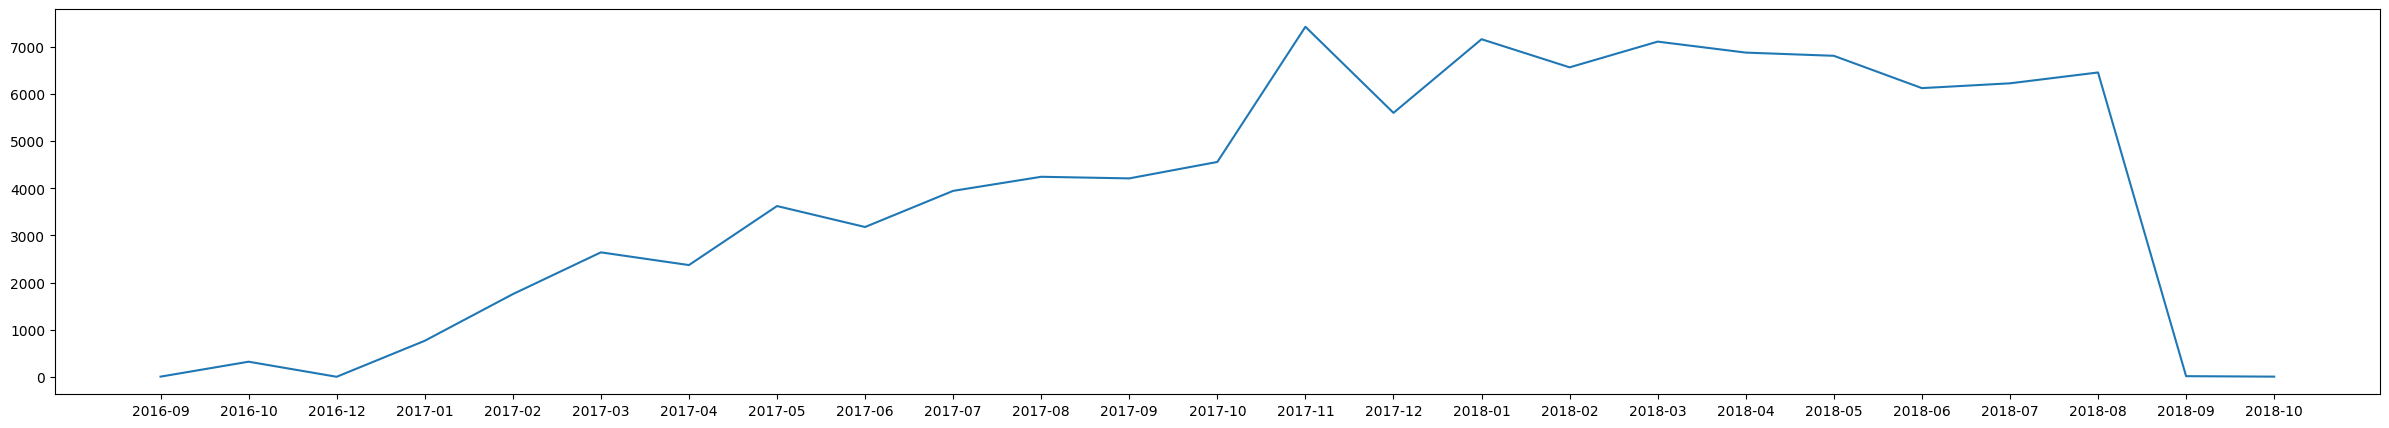

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(30, 5))
plt.plot(MAU.index.astype('str'), MAU)

plt.show()

MAU быстро растёт в течение 2017 года, резко подскакивает в ноябре 2017 и в 2018 году держится на уровне 6–7 тыс. Провалы в начале и в конце графика вызваны неполными месяцами.

### 4.5. Повторные покупки и Repeat Purchase Rate

In [ ]:
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order,month,day,week
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71,2017-10,2017-10-02,2017-10-02/2017-10-08
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46,2018-07,2018-07-24,2018-07-23/2018-07-29
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12,2018-08,2018-08-08,2018-08-06/2018-08-12
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20,2017-11,2017-11-18,2017-11-13/2017-11-19
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62,2018-02,2018-02-13,2018-02-12/2018-02-18
...,...,...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08,2017-03,2017-03-09,2017-03-06/2017-03-12
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00,2018-02,2018-02-06,2018-02-05/2018-02-11
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01,2017-08,2017-08-27,2017-08-21/2017-08-27
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16,2018-01,2018-01-08,2018-01-08/2018-01-14


In [ ]:
count_order_for_each_customer = data_for_work.groupby('customer_unique_id')['order_id'].count()
count_order_for_each_customer.shape[0]

96096

In [ ]:
l_1 = len(count_order_for_each_customer[count_order_for_each_customer == 1])
print(f'Количество пользователей с 1 заказом составляет: {l_1}')

Количество пользователей с 1 заказом составляет: 93099


In [ ]:
c = [1, 2, 3, 5]
for i in c:
  l = len(count_order_for_each_customer[count_order_for_each_customer >= i])
  print(f'Количество пользователей с {i}+ заказами составляет: {l}')

Количество пользователей с 1+ заказами составляет: 96096
Количество пользователей с 2+ заказами составляет: 2997
Количество пользователей с 3+ заказами составляет: 252
Количество пользователей с 5+ заказами составляет: 19


In [ ]:
l_1 = len(count_order_for_each_customer[count_order_for_each_customer == 1]) / count_order_for_each_customer.shape[0] * 100
print(f'Доля пользователей с 1 заказом составляет: {l_1:.2f}%')

Доля пользователей с 1 заказом составляет: 96.88%


In [ ]:
c = [1, 2, 3, 5]
for i in c:
  l = (len(count_order_for_each_customer[count_order_for_each_customer >= i]) / count_order_for_each_customer.shape[0]) * 100
  print(f'Доля пользователей с {i}+ заказами составляет: {l:.2f}%')

Доля пользователей с 1+ заказами составляет: 100.00%
Доля пользователей с 2+ заказами составляет: 3.12%
Доля пользователей с 3+ заказами составляет: 0.26%
Доля пользователей с 5+ заказами составляет: 0.02%


Repeat Purchase Rate = 3,12%: столько пользователей сделали больше одной покупки.

- 1 заказ: 93 099 клиентов (96,9%)

- 2+ заказа: 2 997 (3,1%)

- 3+ заказа: 252 (0,26%)

- 5+ заказов: 19 (0,02%)

In [ ]:
count_order_for_each_customer.describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,order_id
count,96096.000000
mean,1.034809
std,0.214384
min,1.000000
1%,1.000000
5%,1.000000
10%,1.000000
25%,1.000000
50%,1.000000
75%,1.000000


In [ ]:
count_order_for_each_customer.value_counts()

,count
order_id,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


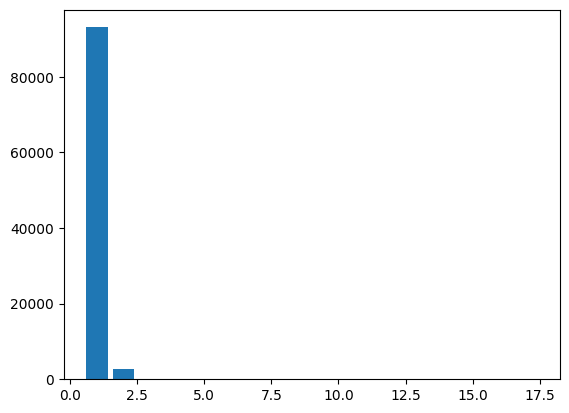

In [ ]:
counts = count_order_for_each_customer.value_counts().sort_index()
plt.bar(counts.index, counts.values)
plt.show()

Даже 99-й перцентиль количества заказов на клиента равен двум. Следовательно, в рассматриваемых данных большинство покупателей ограничивается одним заказом. Дальше проверим этот результат с помощью когортного анализа.

### 4.6. Декомпозиция выручки

Проверим формулу *Revenue = Paying Users × Orders per Paying User × AOV*. Декомпозиция помогает понять, какой из множителей двигает выручку.

In [ ]:
statistic_for_revenue = data_for_work.groupby('month').agg(Revenue=('payment_order', 'sum'),
                                   Paying_Users=('customer_unique_id', lambda x: x[data_for_work.loc[x.index, 'payment_order'] > 0].nunique()),
                                   Orders=('order_id', 'count'),
                                   )
statistic_for_revenue['order_per_users'] = statistic_for_revenue['Orders'] / statistic_for_revenue['Paying_Users']
statistic_for_revenue['AOV'] = statistic_for_revenue['Revenue'] / statistic_for_revenue['Orders']


In [ ]:
statistic_for_revenue['Revenue_formula'] = round(statistic_for_revenue['Paying_Users'] * statistic_for_revenue['order_per_users'] * statistic_for_revenue['AOV'],2)
statistic_for_revenue

,Revenue,Paying_Users,Orders,order_per_users,AOV,Revenue_formula
month,,,,,,
2016-09,252.24,3,4,1.333333,63.060000,252.24
2016-10,59090.48,321,324,1.009346,182.378025,59090.48
2016-12,19.62,1,1,1.000000,19.620000,19.62
2017-01,138488.04,765,800,1.045752,173.110050,138488.04
2017-02,291908.01,1755,1780,1.014245,163.993264,291908.01
2017-03,449863.60,2642,2682,1.015140,167.734377,449863.60
2017-04,417788.03,2372,2404,1.013491,173.788698,417788.03
2017-05,592918.82,3625,3700,1.020690,160.248330,592918.82
2017-06,511276.38,3180,3245,1.020440,157.558206,511276.38


Значения `Revenue_formula` совпали с фактической выручкой по месяцам. Частота покупок остается примерно на уровне 1,01–1,02, а средний чек меняется незначительно. Поэтому рост выручки в 2017 году в основном связан с увеличением числа платящих пользователей.

### 4.7. Когортный анализ: retention

Когорта = месяц первой покупки клиента. `lifetime` = сколько месяцев прошло от первой покупки. Retention = доля клиентов когорты, совершивших покупку на `lifetime`-й месяц.

In [ ]:
data_for_work['COHORT'] = data_for_work.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
data_for_work.groupby('COHORT')['customer_unique_id'].nunique()

,customer_unique_id
COHORT,
2016-09,4
2016-10,321
2016-12,1
2017-01,764
2017-02,1752
2017-03,2636
2017-04,2352
2017-05,3596
2017-06,3139


In [ ]:
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order,month,day,week,COHORT
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71,2017-10,2017-10-02,2017-10-02/2017-10-08,2017-09
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46,2018-07,2018-07-24,2018-07-23/2018-07-29,2018-07
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12,2018-08,2018-08-08,2018-08-06/2018-08-12,2018-08
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20,2017-11,2017-11-18,2017-11-13/2017-11-19,2017-11
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62,2018-02,2018-02-13,2018-02-12/2018-02-18,2018-02
...,...,...,...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08,2017-03,2017-03-09,2017-03-06/2017-03-12,2017-03
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00,2018-02,2018-02-06,2018-02-05/2018-02-11,2018-02
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01,2017-08,2017-08-27,2017-08-21/2017-08-27,2017-08
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16,2018-01,2018-01-08,2018-01-08/2018-01-14,2018-01


In [ ]:
data_for_work['lifetime'] =  (data_for_work['month'].dt.year - data_for_work['COHORT'].dt.year) * 12 + (data_for_work['month'].dt.month - data_for_work['COHORT'].dt.month)
data_for_work

,order_id,customer_unique_id,order_purchase_timestamp,order_status,customer_state,payment_order,month,day,week,COHORT,lifetime
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,delivered,SP,38.71,2017-10,2017-10-02,2017-10-02/2017-10-08,2017-09,1
3,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,delivered,BA,141.46,2018-07,2018-07-24,2018-07-23/2018-07-29,2018-07,0
4,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,delivered,GO,179.12,2018-08,2018-08-08,2018-08-06/2018-08-12,2018-08,0
5,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,delivered,RN,72.20,2017-11,2017-11-18,2017-11-13/2017-11-19,2017-11,0
6,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,delivered,SP,28.62,2018-02,2018-02-13,2018-02-12/2018-02-18,2018-02,0
...,...,...,...,...,...,...,...,...,...,...,...
103882,9c5dedf39a927c1b2549525ed64a053c,6359f309b166b0196dbf7ad2ac62bb5a,2017-03-09 09:54:05,delivered,SP,85.08,2017-03,2017-03-09,2017-03-06/2017-03-12,2017-03,0
103883,63943bddc261676b46f01ca7ac2f7bd8,da62f9e57a76d978d02ab5362c509660,2018-02-06 12:58:58,delivered,SP,195.00,2018-02,2018-02-06,2018-02-05/2018-02-11,2018-02,0
103884,83c1379a015df1e13d02aae0204711ab,737520a9aad80b3fbbdad19b66b37b30,2017-08-27 14:46:43,delivered,BA,271.01,2017-08,2017-08-27,2017-08-21/2017-08-27,2017-08,0
103885,11c177c8e97725db2631073c19f07b62,5097a5312c8b157bb7be58ae360ef43c,2018-01-08 21:28:27,delivered,RJ,441.16,2018-01,2018-01-08,2018-01-08/2018-01-14,2018-01,0


In [ ]:
(data_for_work.groupby(['COHORT', 'lifetime'])['customer_unique_id'].nunique() / data_for_work.groupby(['COHORT'])['customer_unique_id'].nunique()).mul(100).unstack()

lifetime,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
COHORT,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.311526,NaN,NaN,0.311526,NaN,0.311526,NaN,0.311526,NaN,0.311526,NaN,0.311526,0.623053,0.623053
2016-12,100.0,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.392670,0.261780,0.130890,0.392670,0.130890,0.523560,0.130890,0.130890,NaN,0.392670,0.130890,0.785340,0.392670,0.130890,0.130890,0.261780,0.392670,0.130890,NaN
2017-02,100.0,0.228311,0.285388,0.114155,0.399543,0.114155,0.228311,0.171233,0.171233,0.228311,0.114155,0.285388,0.171233,0.171233,0.114155,0.057078,0.057078,0.228311,NaN,NaN
2017-03,100.0,0.493171,0.379363,0.379363,0.341426,0.151745,0.151745,0.303490,0.341426,0.075873,0.379363,0.151745,0.227618,0.113809,0.151745,0.227618,0.075873,0.151745,NaN,NaN
2017-04,100.0,0.595238,0.212585,0.170068,0.340136,0.255102,0.340136,0.297619,0.297619,0.170068,0.255102,0.085034,0.085034,0.042517,0.085034,0.085034,0.212585,NaN,NaN,NaN
2017-05,100.0,0.500556,0.500556,0.389321,0.305895,0.333704,0.417130,0.166852,0.250278,0.305895,0.250278,0.333704,0.250278,0.027809,0.194661,0.250278,NaN,NaN,NaN,NaN
2017-06,100.0,0.477859,0.350430,0.414145,0.254858,0.382287,0.382287,0.223001,0.127429,0.223001,0.318573,0.350430,0.159286,0.127429,0.191144,NaN,NaN,NaN,NaN,NaN


Доля вернувшихся покупателей в первый месяц после первой покупки составляет **0,1–0,7%**, в следующие месяцы она еще ниже. Это согласуется с результатом по повторным покупкам: в данных возвраты встречаются редко.

Для дальнейшего исследования можно рассмотреть программу лояльности, персональные рекомендации и напоминания о покупке. Это пока *гипотезы*, их влияние нужно проверять отдельно.

<a id="part5" name="part5"></a>

## **5. Анализ воронки**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

Отдельный датасет: события пользователей интернет-магазина за январь–март 2026.
Воронка: view → cart → checkout → purchase. Есть сегменты по устройству (`device`) и источнику трафика (`source`).

### 5.1. Знакомство с данными

In [ ]:
funnel_data = pd.read_csv('funnel_events.csv')
funnel_data

,user_id,session_id,event,event_time,device,source
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic
...,...,...,...,...,...,...
14753,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct
14754,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic
14755,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct
14756,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct


In [ ]:
funnel_data.shape

(14758, 6)

In [ ]:
funnel_data.head()

,user_id,session_id,event,event_time,device,source
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic


In [ ]:
funnel_data.describe(include='all')

,user_id,session_id,event,event_time,device,source
count,14758.000000,14758,14758,14758,14758,14758
unique,NaN,6000,4,14746,2,3
top,NaN,s0000164,view,2026-03-23 08:05:33,mobile,organic
freq,NaN,8,8082,2,9911,6769
mean,102985.901613,NaN,NaN,NaN,NaN,NaN
std,1730.123323,NaN,NaN,NaN,NaN,NaN
min,100001.000000,NaN,NaN,NaN,NaN,NaN
25%,101508.000000,NaN,NaN,NaN,NaN,NaN
50%,102965.000000,NaN,NaN,NaN,NaN,NaN
75%,104483.750000,NaN,NaN,NaN,NaN,NaN


In [ ]:
funnel_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14758 entries, 0 to 14757
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     14758 non-null  int64 
 1   session_id  14758 non-null  object
 2   event       14758 non-null  object
 3   event_time  14758 non-null  object
 4   device      14758 non-null  object
 5   source      14758 non-null  object
dtypes: int64(1), object(5)
memory usage: 691.9+ KB


In [ ]:
funnel_data['event_time'] = pd.to_datetime(funnel_data['event_time'])
funnel_data.dtypes

,0
user_id,int64
session_id,object
event,object
event_time,datetime64[ns]
device,object
source,object


In [ ]:
funnel_data.isna().sum()

,0
user_id,0
session_id,0
event,0
event_time,0
device,0
source,0


In [ ]:
funnel_data.duplicated().sum()

np.int64(2)

In [ ]:
funnel_data[funnel_data.duplicated()]

,user_id,session_id,event,event_time,device,source
2726,103426,s0003426,view,2026-01-18 00:14:38,mobile,ads
7635,105610,s0005610,view,2026-02-16 13:26:26,desktop,organic


In [ ]:
funnel_data = funnel_data.drop_duplicates()
funnel_data

,user_id,session_id,event,event_time,device,source
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic
...,...,...,...,...,...,...
14753,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct
14754,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic
14755,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct
14756,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct


In [ ]:
len(funnel_data) == funnel_data.nunique()

,0
user_id,False
session_id,False
event,False
event_time,False
device,False
source,False


In [ ]:
funnel_data.duplicated(subset=['user_id', 'event_time']).sum()

np.int64(0)

Гранулярность: одна строка = одно событие пользователя (`user_id` + `event_time`). Найдено и удалено 2 полных дубликата.

In [ ]:
print(f'Количество уникальных пользователей составляет: {funnel_data['user_id'].nunique()}')
print(f'Количество уникальных сессий составляет: {funnel_data['session_id'].nunique()}')


Количество уникальных пользователей составляет: 6000
Количество уникальных сессий составляет: 6000


In [ ]:
funnel_data['event'].value_counts()

,count
event,
view,8080
cart,3353
checkout,1874
purchase,1449


In [ ]:
funnel_data['device'].value_counts()

,count
device,
mobile,9910
desktop,4846


In [ ]:
funnel_data['source'].value_counts()

,count
source,
organic,6768
ads,5076
direct,2912


In [ ]:
print(f'Минимальное время события: {funnel_data['event_time'].min()}\nМаксимальное время события: {funnel_data['event_time'].max()}')


Минимальное время события: 2026-01-01 00:05:33
Максимальное время события: 2026-03-31 23:53:08


6 000 пользователей и 6 000 сессий, то есть у каждого пользователя одна сессия. Mobile даёт 67% событий. Источники трафика: organic (46%), ads (34%), direct (20%).

### 5.2. Простая воронка

Посчитаем уникальных пользователей на каждом шаге без учёта порядка событий.

In [ ]:
count_event = funnel_data.groupby(['event'])['user_id'].nunique().sort_values(ascending=False)
# list(count_event)
count_event

,user_id
event,
view,6000
cart,3109
checkout,1874
purchase,1425


In [ ]:
cart_view_conversation = round(count_event['cart'] / count_event['view'] * 100, 2)
cart_checkout_conversation = round(count_event['checkout'] / count_event['cart'] * 100, 2)
checkout_purchase_conversation = round(count_event['purchase'] / count_event['checkout'] * 100, 2)
print(f'Конверсия просмотра в корзину составляет: {cart_view_conversation}%\nКонверсия корзины в оформление заказа составляет: {cart_checkout_conversation}%\nКонверсия оформления заказа в покупку составляет: {checkout_purchase_conversation}%')

Конверсия просмотра в корзину составляет: 51.82%
Конверсия корзины в оформление заказа составляет: 60.28%
Конверсия оформления заказа в покупку составляет: 76.04%


| Шаг | Конверсия |
|---|---|
| view → cart | 51,82% |
| cart → checkout | 60,28% |
| checkout → purchase | 76,04% |

In [ ]:
purchase_view_conversation = round(count_event['purchase'] / count_event['view'] * 100, 2)
print(f'Конверсия просмотра в покупку составляет: {purchase_view_conversation}%')

Конверсия просмотра в покупку составляет: 23.75%


In [ ]:
count_event.diff(1) # абсолютные потери пользователей между шагами

,user_id
event,
view,NaN
cart,-2891.0
checkout,-1235.0
purchase,-449.0


In [ ]:
count_event = pd.DataFrame(count_event)

In [ ]:
count_event['before_event'] = count_event['user_id'].shift(1)


In [ ]:
count_event = count_event.rename(columns={'user_id' : 'count_users'})
count_event['conversation_rate'] = round(count_event['count_users'] / count_event['before_event'] * 100, 2)
count_event['drop_of_rate'] = 100 - count_event['conversation_rate']
count_event

,count_users,before_event,conversation_rate,drop_of_rate
event,,,,
view,6000,NaN,NaN,NaN
cart,3109,6000.0,51.82,48.18
checkout,1874,3109.0,60.28,39.72
purchase,1425,1874.0,76.04,23.96


Больше всего пользователей теряется на первом шаге (48% не добавляют товар в корзину). Шаг cart → checkout теряет ~40% и стоит рассмотреть его отдельно.

### 5.3. Последовательная (строгая) воронка

Простая воронка засчитывает шаг, даже если события шли не по порядку. Здесь для каждого пользователя возьмем первое событие шага, которое произошло после предыдущего шага: `cart_time > view_time`, `checkout_time > cart_time` и т.д.

In [ ]:
funnel_data = funnel_data.sort_values(by='event_time')

In [ ]:
funnel_data['sort_event_for_each_user'] = (funnel_data.groupby('user_id').cumcount() + 1)
funnel_data.sort_values(by=['user_id', 'event_time'])

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user
13594,100001,s0000001,view,2026-03-24 21:44:56,desktop,ads,1
7642,100002,s0000002,view,2026-02-16 15:01:18,mobile,organic,1
7643,100002,s0000002,cart,2026-02-16 15:09:56,mobile,organic,2
7647,100002,s0000002,checkout,2026-02-16 15:29:01,mobile,organic,3
7649,100002,s0000002,purchase,2026-02-16 15:31:46,mobile,organic,4
...,...,...,...,...,...,...,...
12671,105999,s0005999,view,2026-03-19 11:29:37,desktop,direct,1
12672,105999,s0005999,view,2026-03-19 11:35:37,desktop,direct,2
12675,105999,s0005999,view,2026-03-19 11:43:25,desktop,direct,3
1436,106000,s0006000,view,2026-01-10 06:03:49,desktop,ads,1


In [ ]:
view_time = funnel_data[funnel_data['event'] == 'view'].groupby(['user_id'])['event_time'].min()
view_time.name = 'view_time'
view_time

,view_time
user_id,
100001,2026-03-24 21:44:56
100002,2026-02-16 15:01:18
100003,2026-02-25 06:28:44
100004,2026-02-01 19:50:57
100005,2026-03-22 03:50:50
...,...
105996,2026-03-19 03:10:10
105997,2026-01-21 20:28:57
105998,2026-02-01 06:43:07


In [ ]:
funnel_data = funnel_data.merge(view_time, on='user_id', how='left')


In [ ]:
funnel_data

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57
...,...,...,...,...,...,...,...,...
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35
14752,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic,2,2026-03-31 23:19:58
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35


In [ ]:
cart_time = funnel_data[funnel_data['event'] == 'cart'].query('event_time > view_time').groupby('user_id')['event_time'].min()
cart_time.name = 'cart_time'
funnel_data = funnel_data.merge(cart_time, on='user_id', how='left')
funnel_data

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time,cart_time
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33,NaT
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11,NaT
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38,NaT
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38,NaT
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57,2026-01-01 00:51:52
...,...,...,...,...,...,...,...,...,...
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35,NaT
14752,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic,2,2026-03-31 23:19:58,2026-03-31 23:41:05
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52,NaT
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35,NaT


In [ ]:
checkout_time = funnel_data[funnel_data['event'] == 'checkout'].query('event_time > cart_time').groupby('user_id')['event_time'].min()
checkout_time.name = 'checkout_time'
funnel_data = funnel_data.merge(checkout_time, on='user_id', how='left')
funnel_data

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time,cart_time,checkout_time
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33,NaT,NaT
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11,NaT,NaT
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38,NaT,NaT
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38,NaT,NaT
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57,2026-01-01 00:51:52,2026-01-01 01:07:55
...,...,...,...,...,...,...,...,...,...,...
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35,NaT,NaT
14752,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic,2,2026-03-31 23:19:58,2026-03-31 23:41:05,NaT
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52,NaT,NaT
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35,NaT,NaT


In [ ]:
purchase_time = funnel_data[funnel_data['event'] == 'purchase'].query('event_time > checkout_time').groupby('user_id')['event_time'].min()
purchase_time.name = 'purchase_time'
funnel_data = funnel_data.merge(purchase_time, on='user_id', how='left')
funnel_data

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time,cart_time,checkout_time,purchase_time
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33,NaT,NaT,NaT
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11,NaT,NaT,NaT
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38,NaT,NaT,NaT
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38,NaT,NaT,NaT
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57,2026-01-01 00:51:52,2026-01-01 01:07:55,NaT
...,...,...,...,...,...,...,...,...,...,...,...
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35,NaT,NaT,NaT
14752,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic,2,2026-03-31 23:19:58,2026-03-31 23:41:05,NaT,NaT
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52,NaT,NaT,NaT
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35,NaT,NaT,NaT


In [ ]:
funnel_data[funnel_data['purchase_time'].notna()]['user_id'].nunique()

1378

In [ ]:
funnel_data[funnel_data['checkout_time'].notna()]['user_id'].nunique()

1839

In [ ]:
funnel_data[funnel_data['cart_time'].notna()]['user_id'].nunique()

3109

In [ ]:
view_count = funnel_data[funnel_data['view_time'].notna()]['user_id'].nunique()
cart_count = funnel_data[funnel_data['cart_time'].notna()]['user_id'].nunique()
checkout_count = funnel_data[funnel_data['checkout_time'].notna()]['user_id'].nunique()
purchase_count = funnel_data[funnel_data['purchase_time'].notna()]['user_id'].nunique()
s = [view_count, cart_count, checkout_count, purchase_count]

In [ ]:
print(cart_count / view_count * 100)
print(checkout_count / cart_count * 100)
print(purchase_count / checkout_count * 100)
print(purchase_count / view_count * 100)

51.81666666666666
59.15085236410421
74.93202827623708
22.966666666666665


Сравнение простой и строгой воронки:

| Шаг | Простая | Строгая |
|---|---|---|
| view → cart | 51,82% | 51,82% |
| cart → checkout | 60,28% | 59,15% |
| checkout → purchase | 76,04% | 74,93% |
| view → purchase | 23,75% | 22,97% |

Строгая воронка даёт чуть более низкие конверсии: у части пользователей события записаны не по порядку (например, checkout без предшествующей корзины). Дальше используем строгую воронку как более корректную.

### 5.4. Воронка в разрезе устройств

In [ ]:

funnel_data[funnel_data['device'] == 'mobile']

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time,cart_time,checkout_time,purchase_time
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33,NaT,NaT,NaT
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11,NaT,NaT,NaT
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38,NaT,NaT,NaT
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38,NaT,NaT,NaT
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57,2026-01-01 00:51:52,2026-01-01 01:07:55,NaT
...,...,...,...,...,...,...,...,...,...,...,...
14749,103827,s0003827,view,2026-03-31 23:22:52,mobile,direct,1,2026-03-31 23:22:52,NaT,NaT,NaT
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35,NaT,NaT,NaT
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52,NaT,NaT,NaT
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35,NaT,NaT,NaT


In [ ]:
count_unique_device = funnel_data.groupby('user_id')['device'].nunique()
count_unique_device[count_unique_device > 1 ].count()

np.int64(0)

In [ ]:
devices = funnel_data['device'].value_counts().index.tolist()
for device in devices:
  funnel_data_device = funnel_data[funnel_data['device'] == device]
  view = funnel_data_device[funnel_data_device['view_time'].notna()]['user_id'].nunique()
  cart = funnel_data_device[funnel_data_device['cart_time'].notna()]['user_id'].nunique()
  checkout = funnel_data_device[funnel_data_device['checkout_time'].notna()]['user_id'].nunique()
  purchase = funnel_data_device[funnel_data_device['purchase_time'].notna()]['user_id'].nunique()
  print(f'Для device = {device}')
  print(f'Конверсия view → cart составляет: {cart / view * 100: .2f}')
  print(f'Конверсия cart → checkout составляет: {checkout / cart * 100: .2f}')
  print(f'Конверсия checkout → purchase составляет: {purchase / checkout * 100: .2f}')
  print(f'Конверсия view → purchase составляет: {purchase / view * 100: .2f}')
  print('\n')

Для device = mobile
Конверсия view → cart составляет:  50.46
Конверсия cart → checkout составляет:  56.43
Конверсия checkout → purchase составляет:  73.98
Конверсия view → purchase составляет:  21.07


Для device = desktop
Конверсия view → cart составляет:  54.81
Конверсия cart → checkout составляет:  64.68
Конверсия checkout → purchase составляет:  76.62
Конверсия view → purchase составляет:  27.17




Каждый пользователь заходит только с одного устройства, поэтому сегменты не пересекаются.

| Шаг | mobile | desktop |
|---|---|---|
| view → cart | 50,46% | 54,81% |
| cart → checkout | 56,43% | 64,68% |
| checkout → purchase | 73,98% | 76,62% |
| view → purchase | 21,07% | 27,17% |

Mobile отстаёт на всех шагах, больше всего на cart → checkout (−8 п.п.).

### 5.5. Воронка в разрезе источников трафика

In [ ]:
count_unique_source = funnel_data.groupby('user_id')['source'].nunique()
count_unique_source[count_unique_source > 1].count()

np.int64(0)

In [ ]:
sources = funnel_data['source'].value_counts().index.tolist()
for source in sources:
  funnel_data_sourse = funnel_data[funnel_data['source'] == source]
  view = funnel_data_sourse[funnel_data_sourse['view_time'].notna()]['user_id'].nunique()
  cart = funnel_data_sourse[funnel_data_sourse['cart_time'].notna()]['user_id'].nunique()
  checkout = funnel_data_sourse[funnel_data_sourse['checkout_time'].notna()]['user_id'].nunique()
  purchase = funnel_data_sourse[funnel_data_sourse['purchase_time'].notna()]['user_id'].nunique()
  print(f'Для source = {source}')
  print(f'Конверсия view → cart составляет: {cart / view * 100: .2f}')
  print(f'Конверсия cart → checkout составляет: {checkout / cart * 100: .2f}')
  print(f'Конверсия checkout → purchase составляет: {purchase / checkout * 100: .2f}')
  print(f'Конверсия view → purchase составляет: {purchase / view * 100: .2f}')
  print('\n')

Для source = organic
Конверсия view → cart составляет:  54.52
Конверсия cart → checkout составляет:  60.20
Конверсия checkout → purchase составляет:  74.83
Конверсия view → purchase составляет:  24.56


Для source = ads
Конверсия view → cart составляет:  49.02
Конверсия cart → checkout составляет:  55.77
Конверсия checkout → purchase составляет:  74.70
Конверсия view → purchase составляет:  20.42


Для source = direct
Конверсия view → cart составляет:  50.72
Конверсия cart → checkout составляет:  62.52
Конверсия checkout → purchase составляет:  75.54
Конверсия view → purchase составляет:  23.96




Самый слабый канал ads (view → purchase 20,4% против 24,6% у organic). Он проигрывает на шагах view → cart и cart → checkout.

### 5.6. Динамика конверсий по месяцам

Месяц пользователя определим по дате его первого просмотра.

In [ ]:
funnel_data['month'] = funnel_data['view_time'].dt.to_period('M')
funnel_data

,user_id,session_id,event,event_time,device,source,sort_event_for_each_user,view_time,cart_time,checkout_time,purchase_time,month
0,103684,s0003684,view,2026-01-01 00:05:33,mobile,organic,1,2026-01-01 00:05:33,NaT,NaT,NaT,2026-01
1,100979,s0000979,view,2026-01-01 00:16:11,mobile,ads,1,2026-01-01 00:16:11,NaT,NaT,NaT,2026-01
2,102401,s0002401,view,2026-01-01 00:25:38,mobile,ads,1,2026-01-01 00:25:38,NaT,NaT,NaT,2026-01
3,102401,s0002401,view,2026-01-01 00:27:42,mobile,ads,2,2026-01-01 00:25:38,NaT,NaT,NaT,2026-01
4,105543,s0005543,view,2026-01-01 00:33:57,mobile,organic,1,2026-01-01 00:33:57,2026-01-01 00:51:52,2026-01-01 01:07:55,NaT,2026-01
...,...,...,...,...,...,...,...,...,...,...,...,...
14751,103986,s0003986,view,2026-03-31 23:37:35,mobile,direct,1,2026-03-31 23:37:35,NaT,NaT,NaT,2026-03
14752,102577,s0002577,cart,2026-03-31 23:41:05,desktop,organic,2,2026-03-31 23:19:58,2026-03-31 23:41:05,NaT,NaT,2026-03
14753,103827,s0003827,purchase,2026-03-31 23:45:17,mobile,direct,2,2026-03-31 23:22:52,NaT,NaT,NaT,2026-03
14754,103986,s0003986,view,2026-03-31 23:46:48,mobile,direct,2,2026-03-31 23:37:35,NaT,NaT,NaT,2026-03


In [ ]:
c = ['view_time', 'cart_time', 'checkout_time', 'purchase_time']
for i in range(len(c) - 1):
  time1 = c[i]
  time2 = c[i + 1]
  df1 = funnel_data[funnel_data[time1].notna()].groupby('month')['user_id'].nunique()
  df2 = funnel_data[funnel_data[time2].notna()].groupby('month')['user_id'].nunique()
  df = round(df2 / df1 * 100, 2)
  df.name = 'Конверсия по месяцам'
  print(f'Конверсия {time1} → {time2} по месяцам:')
  print(df)
  print('\n')


Конверсия view_time → cart_time по месяцам:
month
2026-01    51.24
2026-02    51.78
2026-03    52.43
Freq: M, Name: Конверсия по месяцам, dtype: float64


Конверсия cart_time → checkout_time по месяцам:
month
2026-01    61.40
2026-02    59.08
2026-03    57.01
Freq: M, Name: Конверсия по месяцам, dtype: float64


Конверсия checkout_time → purchase_time по месяцам:
month
2026-01    72.42
2026-02    75.17
2026-03    77.36
Freq: M, Name: Конверсия по месяцам, dtype: float64




In [ ]:
c = ['view_time','purchase_time']
for i in range(len(c) - 1):
  time1 = c[i]
  time2 = c[i + 1]
  df1 = funnel_data[funnel_data[time1].notna()].groupby('month')['user_id'].nunique()
  df2 = funnel_data[funnel_data[time2].notna()].groupby('month')['user_id'].nunique()
  df = round(df2 / df1 * 100, 2)
  df.name = 'Конверсия по месяцам'
  print(f'Конверсия {time1} → {time2} по месяцам:')
  print(df)
  print('\n')

Конверсия view_time → purchase_time по месяцам:
month
2026-01    22.78
2026-02    23.00
2026-03    23.13
Freq: M, Name: Конверсия по месяцам, dtype: float64




Шаги view → cart и checkout → purchase растут, а cart → checkout падает: 61,4% → 59,1% → 57,0%. Сквозная конверсия при этом почти не меняется (22,8% → 23,0% → 23,1%), потому что улучшения на других шагах маскируют просадку. Рассмотрим этот шаг подробнее.

### 5.7. Поиск причины просадки cart → checkout

Сначала разделим шаг по устройствам, затем посмотрим mobile по источникам трафика.

In [ ]:
funnel_data['device'].unique().tolist()

['mobile', 'desktop']

In [ ]:
time = ['cart_time', 'checkout_time']
devices = funnel_data['device'].unique().tolist()
for i in range(len(time) - 1):
  for device in devices:
    time1 = time[i]
    time2 = time[i + 1]
    funnel_data_device = funnel_data[funnel_data['device'] == device]
    df1 = funnel_data_device[funnel_data_device[time1].notna()].groupby('month')['user_id'].nunique()
    df2 = funnel_data_device[funnel_data_device[time2].notna()].groupby('month')['user_id'].nunique()
    df = round(df2 / df1 * 100, 2)
    df.name = 'Конверсия по месяцам'
    print(f'Конверсия {time1} → {time2} для устройства {device} по месяцам:')
    print(df)
    print('\n')


Конверсия cart_time → checkout_time для устройства mobile по месяцам:
month
2026-01    61.47
2026-02    57.10
2026-03    51.02
Freq: M, Name: Конверсия по месяцам, dtype: float64


Конверсия cart_time → checkout_time для устройства desktop по месяцам:
month
2026-01    61.25
2026-02    62.87
2026-03    70.00
Freq: M, Name: Конверсия по месяцам, dtype: float64




Просадка полностью приходится на mobile: 61,5% → 57,1% → 51,0%. На desktop конверсия наоборот растёт: 61,3% → 70,0%.

In [ ]:
time = ['cart_time', 'checkout_time']
sources = funnel_data['source'].unique().tolist()
funnel_data_mobile = funnel_data[funnel_data['device'] == 'mobile']
for i in range(len(time) - 1):
  for source in sources:
    time1 = time[i]
    time2 = time[i + 1]
    funnel_data_source = funnel_data_mobile[funnel_data_mobile['source'] == source]
    df1 = funnel_data_source[funnel_data_source[time1].notna()].groupby('month')['user_id'].nunique()
    df2 = funnel_data_source[funnel_data_source[time2].notna()].groupby('month')['user_id'].nunique()
    df = round(df2 / df1 * 100, 2)
    df.name = 'Конверсия по месяцам'
    print(f'Конверсия {time1} → {time2} для устройства mobile через канал {source} по месяцам:')
    print(df)
    print('\n')


Конверсия cart_time → checkout_time для устройства mobile через канал organic по месяцам:
month
2026-01    60.71
2026-02    54.69
2026-03    55.90
Freq: M, Name: Конверсия по месяцам, dtype: float64


Конверсия cart_time → checkout_time для устройства mobile через канал ads по месяцам:
month
2026-01    60.18
2026-02    56.87
2026-03    41.70
Freq: M, Name: Конверсия по месяцам, dtype: float64


Конверсия cart_time → checkout_time для устройства mobile через канал direct по месяцам:
month
2026-01    65.28
2026-02    64.55
2026-03    56.41
Freq: M, Name: Конверсия по месяцам, dtype: float64




<u>Вывод по шагу cart → checkout на mobile</u>

| Канал | Январь | Февраль | Март |
|---|---|---|---|
| organic | 60,7% | 54,7% | 55,9% |
| ads | 60,2% | 56,9% | 41,7% |
| direct | 65,3% | 64,6% | 56,4% |

От января к марту конверсия снизилась во всех трех каналах. Сильнее всего — у ads: с 60,2% до 41,7%, то есть на 18,5 п.п. Возможны проблемы с мобильным оформлением заказа или изменения в составе рекламного трафика, но по этой таблице определить причину нельзя.

Дальше стоило бы посмотреть версии приложения, операционные системы, изменения мобильного сайта и рекламные кампании за февраль–март.

In [ ]:
f = funnel_data[funnel_data['view_time'].notna()].groupby('month')['user_id'].nunique()
f.name = 'Пользователи в начале воронки'
f

,Пользователи в начале воронки
month,
2026-01,2063
2026-02,1883
2026-03,2054


Количество пользователей, начавших воронку, по месяцам стабильно (1 883–2 063 в месяц), поэтому изменения конверсий не связаны с резким изменением объёма трафика.

<a id="part6" name="part6"></a>

## **6. A/B-тестирование bootstrap и A/A-тестирование**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

Раздел на синтетических данных. Цель: на симуляциях разобраться, как работают статистические тесты, и проверить ключевые свойства:
ошибку I рода, мощность, MDE, размер выборки, тесты для конверсий и для непрерывных метрик, бутстрап и SRM.

### 6.1. A/A-тест на конверсии

Сгенерируем две группы по 10 000 пользователей с одинаковой истинной конверсией 10%.

In [ ]:
import numpy as np

In [ ]:
rng = np.random.default_rng(42)


In [ ]:
A = rng.binomial(n=1, p=0.1, size=10000)
B = rng.binomial(n=1, p=0.1, size=10000)

In [ ]:
conversation_A = A.mean()
conversation_B = B.mean()
print(f'Конверсия для группы A: {conversation_A}, конверсия для группы B: {conversation_B}')

Конверсия для группы A: 0.0985, конверсия для группы B: 0.1006


In [ ]:
absolute_uplift = (conversation_B - conversation_A)
absolute_uplift

np.float64(0.0020999999999999908)

In [ ]:
relative_uplift = (conversation_B - conversation_A) / conversation_A
relative_uplift

np.float64(0.021319796954314626)

Обе группы сгенерированы из одного распределения, но наблюдаемые конверсии отличаются (9,85% против 10,06%, относительная разница +2,1%). Эта разница вызвана только случайным шумом.

В этом смысл A/A-теста: он показывает, какой разброс метрики даёт шум, и проверяет, что система сплитования и статистический тест не находят эффект там, где его нет.

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

#### Z-тест для двух долей

- H₀: conversion_A = conversion_B

- H₁: conversion_A ≠ conversion_B (двусторонняя альтернатива)

- Уровень значимости α = 0,05

In [ ]:
counts_a = np.sum(A)
counts_b = np.sum(B)
nobs_a = A.size
nobs_b = B.size


In [ ]:
proportions_ztest(count=[counts_a, counts_b], nobs=[nobs_a, nobs_b])

(np.float64(-0.49596823631239423), np.float64(0.6199168215050339))

Получили **p-value ≈ 0,62 > 0,05**, поэтому нулевую гипотезу не отвергаем. Статистически значимых различий между конверсиями не обнаружено.

Если реальные конверсии одинаковы, вероятность получить такую же или более сильную разницу по модулю составляет около 62%. Это не вероятность того, что нулевая гипотеза верна.

### 6.2. Распределение p-value и ошибка I рода

Повторим A/A-тест 1 000 раз и посмотрим, как распределено p-value и как часто тест ошибочно находит «эффект».

In [ ]:
p_values = []
for i in range(1000):
  rng = np.random.default_rng()
  A = rng.binomial(n=1, p=0.1, size=1000)
  B = rng.binomial(n=1, p=0.1, size=1000)
  counts_a = np.sum(A)
  counts_b = np.sum(B)
  nobs_a = A.size
  nobs_b = B.size
  p_value = proportions_ztest(count=[counts_a, counts_b], nobs=[nobs_a, nobs_b])[1]
  p_values.append(p_value)



In [ ]:
p_values = pd.Series(p_values)
p_values.name = 'p_value'
p_values

,p_value
0,0.940452
1,0.647267
2,0.758110
3,0.379394
4,0.460008
...,...
995,0.882016
996,0.458045
997,0.402651
998,0.939068


In [ ]:
len(p_values[p_values < 0.05]) / len(p_values)

0.05

В симуляции доля p-value < 0,05 составила **5%**, что близко к заданному уровню значимости. То есть тест иногда находит различия даже при одинаковой истинной конверсии — это ошибка первого рода.

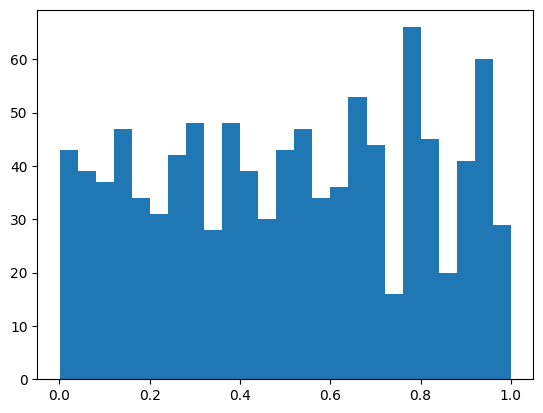

In [ ]:
import matplotlib.pyplot as plt
plt.hist(x=p_values, bins=25)
plt.show()

На гистограмме p-value распределены примерно равномерно. При верной нулевой гипотезе для корректно откалиброванного непрерывного теста ожидается равномерное распределение на отрезке [0; 1]. Для теста долей это приближение, которое здесь работает при больших выборках.

Поэтому при уровне значимости 0,05 примерно в 5% таких экспериментов тест может ошибочно показать значимое различие.

### 6.3. A/B-тест с реальным эффектом

Контроль: конверсия 10%, тест: 11% (абсолютный эффект +1 п.п., относительный +10%). По 5 000 пользователей в группе.

In [ ]:
rng = np.random.default_rng(42)
control = rng.binomial(n=1, p=0.1, size=5000)
test = rng.binomial(n=1, p=0.11, size=5000 )


In [ ]:
# Рассчитаем конверсии для групп
conversation_control = control.mean()
conversation_test = test.mean()
absolute_uplift_1 = conversation_test - conversation_control
relative_uplift_1 = (conversation_test - conversation_control) / conversation_control
print(f'Абсолютная разница составляет {absolute_uplift_1}\nОтносительная разница составляет {relative_uplift_1}')

Абсолютная разница составляет 0.008400000000000005
Относительная разница составляет 0.08519269776876273


In [ ]:
count_control = np.sum(control)
count_test = np.sum(test)
nobs_control = control.size
nobs_test = test.size
z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
t_v = z_test[0]
p_value = z_test[1]
print(f'Наблюдаемое значение z-статистики: {t_v}\np-value: {p_value}')

Наблюдаемое значение z-статистики: -1.3829551649195506
p-value: 0.16667861379176174


В симуляции истинная конверсия тестовой группы выше, но **p-value ≈ 0,17 > 0,05**. Нулевую гипотезу не отвергаем. В этом эксперименте тест не обнаружил заданный эффект — получилась ошибка второго рода.

Посмотрим, как часто тест находит этот эффект при повторении эксперимента.

### 6.4. Мощность теста и размер выборки

Мощность = доля экспериментов, в которых тест находит существующий эффект (p < 0,05). Оценим её симуляцией из 1 000 экспериментов.

In [ ]:
all_p_values = []
for i in range(1000):
  control = rng.binomial(n=1, p=0.1, size=5000)
  test = rng.binomial(n=1, p=0.11, size=5000)
  count_control = np.sum(control)
  count_test = np.sum(test)
  nobs_control = control.size
  nobs_test = test.size
  z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
  p_value = z_test[1]
  all_p_values.append(p_value)


In [ ]:
all_p_values = pd.Series(all_p_values)
len(all_p_values[all_p_values < 0.05]) / len(all_p_values)

0.38

При 5 000 пользователях в каждой группе тест обнаружил эффект примерно в **38%** симуляций. Значит, оценка мощности составляет около 38%, а вероятности ошибки второго рода — около 62%.

Это ниже выбранного ориентира 80%. Увеличим размер групп до 10 000 и 15 000 и сравним результаты.

In [ ]:
  all_p_values_10000 = []
  for i in range(1000):
    control = rng.binomial(n=1, p=0.1, size=10000)
    test = rng.binomial(n=1, p=0.11, size=10000)
    count_control = np.sum(control)
    count_test = np.sum(test)
    nobs_control = control.size
    nobs_test = test.size
    z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
    p_value = z_test[1]
    all_p_values_10000.append(p_value)


In [ ]:
all_p_values_10000 = pd.Series(all_p_values_10000)
power_10000 = len(all_p_values_10000[all_p_values_10000 < 0.05]) / len(all_p_values_10000) * 100
print(f'Мощность теста при 10 000 пользователей на группу: {power_10000:.1f}%\nОшибка второго рода: {100 - power_10000:.1f}%')

Мощность теста при 10 000 пользователей на группу: 63.9%
Ошибка второго рода: 36.1%


In [ ]:
  all_p_values_15000 = []
  for i in range(1000):
    control = rng.binomial(n=1, p=0.1, size=15000)
    test = rng.binomial(n=1, p=0.11, size=15000)
    count_control = np.sum(control)
    count_test = np.sum(test)
    nobs_control = control.size
    nobs_test = test.size
    z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
    p_value = z_test[1]
    all_p_values_15000.append(p_value)


In [ ]:
all_p_values_15000 = pd.Series(all_p_values_15000)
power_15000 = len(all_p_values_15000[all_p_values_15000 < 0.05]) / len(all_p_values_15000) * 100
print(f'Мощность теста при 15 000 пользователей на группу: {power_15000:.1f}%\nОшибка второго рода: {100 - power_15000:.1f}%')

Мощность теста при 15 000 пользователей на группу: 78.8%
Ошибка второго рода: 21.2%


| Размер группы | Мощность | Ошибка II рода (β) |
|---|---|---|
| 5 000 | ~38% | ~62% |
| 10 000 | 63,9% | 36,1% |
| 15 000 | 78,8% | 21,2% |

При увеличении выборки в 2 раза мощность выросла примерно в 1,7 раза, при увеличении в 3 раза примерно в 2,1 раза. Ошибка II рода уменьшилась в ~1,7 и ~2,9 раза соответственно. Зависимость нелинейная: чем ближе мощность к 100%, тем медленнее она растёт.

### 6.5. Мощность в зависимости от размера эффекта (MDE)

Зафиксируем выборку 10 000 на группу и изменим абсолютный эффект: +0,2; +0,5; +1; +2 п.п.

In [ ]:
mdes = [0.002, 0.005, 0.01, 0.02]
for mde in mdes:
  all_p_values = []
  for i in range(1000):
    control = rng.binomial(n=1, p=0.1, size=10000)
    test = rng.binomial(n=1, p=0.1 + mde, size=10000)
    count_control = np.sum(control)
    count_test = np.sum(test)
    nobs_control = control.size
    nobs_test = test.size
    z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
    p_value = z_test[1]
    all_p_values.append(p_value)
  all_p_values_series = pd.Series(all_p_values)
  power_10000 = round(len(all_p_values_series[all_p_values_series < 0.05]) / len(all_p_values_series) * 100, 2)
  print(f'Мощность теста при эффекте {mde} составляет: {power_10000}%')


Мощность теста при эффекте 0.002 составляет: 7.4%
Мощность теста при эффекте 0.005 составляет: 21.8%
Мощность теста при эффекте 0.01 составляет: 62.5%
Мощность теста при эффекте 0.02 составляет: 99.2%


При одной и той же выборке мелкие эффекты почти не обнаруживаются (+0,2 п.п.: мощность 7%), а крупные обнаруживаются почти всегда (+2 п.п.: 99%).

Дальше найдем MDE (Minimum Detectable Effect): минимальный эффект, который тест находит с мощностью ≥ 80%, для разных размеров выборки.

In [ ]:
mdes = np.arange(0.001, 0.021, 0.001)
N = np.arange(5000, 25000, 5000)
for n in N:
  all_mdes = []
  for mde in mdes:
    all_p_values = []
    for i in range(1000):
      control = rng.binomial(n=1, p=0.1, size=n)
      test = rng.binomial(n=1, p=0.1 + mde, size=n)
      count_control = np.sum(control)
      count_test = np.sum(test)
      nobs_control = control.size
      nobs_test = test.size
      z_test = proportions_ztest(count=[count_control, count_test], nobs=[nobs_control, nobs_test])
      p_value = z_test[1]
      all_p_values.append(p_value)
    all_p_values_series = pd.Series(all_p_values)
    power = round(len(all_p_values_series[all_p_values_series < 0.05]) / len(all_p_values_series) * 100, 2)
    if power >= 80:
      all_mdes.append(mde)
  print(f'При мощности не меньше 80% и размере выборки {n} минимальный обнаруживаемый эффект (MDE) равен {(np.min(all_mdes))} ')

При мощности не меньше 80% и размере выборки 5000 минимальный обнаруживаемый эффект (MDE) равен 0.018000000000000002 
При мощности не меньше 80% и размере выборки 10000 минимальный обнаруживаемый эффект (MDE) равен 0.013000000000000001 
При мощности не меньше 80% и размере выборки 15000 минимальный обнаруживаемый эффект (MDE) равен 0.011 
При мощности не меньше 80% и размере выборки 20000 минимальный обнаруживаемый эффект (MDE) равен 0.009000000000000001 


| Размер группы | MDE (абс.) при power ≥ 80% |
|---|---|
| 5 000 | 1,8 п.п. |
| 10 000 | 1,3 п.п. |
| 15 000 | 1,1 п.п. |
| 20 000 | 0,9 п.п. |

MDE убывает пропорционально 1/√N: при увеличении выборки в 2 раза MDE уменьшается в √2 ≈ 1,4 раза (1,8 → 1,3), а при увеличении в 4 раза уменьшается в 2 раза (1,8 → 0,9).

С 5 000 пользователей на группу тест надёжно замечает только относительно крупные изменения, а с 20 000 уже гораздо более мелкие. Большая выборка не уменьшает истинный эффект, она уменьшает шум оценки и повышает чувствительность теста.

### 6.6. Аналитический расчёт размера выборки

Проверим результаты симуляций через `statsmodels`: `proportion_effectsize` (Cohen's h) и `NormalIndPower().solve_power` при α = 0,05 и power = 0,8.

In [ ]:
from statsmodels.stats.power import NormalIndPower

from statsmodels.stats.proportion import proportion_effectsize

In [ ]:
import math
for mde in mdes:
  power = 0.8
  alpha = 0.05
  p_control = 0.1
  p_test = p_control + mde
  effect_size = proportion_effectsize(p_test, p_control)
  analysis = NormalIndPower()
  n = analysis.solve_power(
      effect_size=effect_size,
      alpha=alpha,
      power=power,
      ratio=1,
      alternative='two-sided'
  )
  print(f'Для эффекта {round(mde,4)} нужно {math.ceil(n)} пользователей на группу')

Для эффекта 0.001 нужно 1419062 пользователей на группу
Для эффекта 0.002 нужно 356327 пользователей на группу
Для эффекта 0.003 нужно 159059 пользователей на группу
Для эффекта 0.004 нужно 89858 пользователей на группу
Для эффекта 0.005 нужно 57756 пользователей на группу
Для эффекта 0.006 нужно 40279 пользователей на группу
Для эффекта 0.007 нужно 29718 пользователей на группу
Для эффекта 0.008 нужно 22848 пользователей на группу
Для эффекта 0.009 нужно 18128 пользователей на группу
Для эффекта 0.01 нужно 14745 пользователей на группу
Для эффекта 0.011 нужно 12236 пользователей на группу
Для эффекта 0.012 нужно 10323 пользователей на группу
Для эффекта 0.013 нужно 8832 пользователей на группу
Для эффекта 0.014 нужно 7646 пользователей на группу
Для эффекта 0.015 нужно 6687 пользователей на группу
Для эффекта 0.016 нужно 5900 пользователей на группу
Для эффекта 0.017 нужно 5247 пользователей на группу
Для эффекта 0.018 нужно 4698 пользователей на группу
Для эффекта 0.019 нужно 4233 по

Аналитический расчёт совпадает с симуляциями: для эффекта 1,8 п.п. нужно ~4 700 пользователей на группу (симуляция: 5 000), для 1,3 п.п. ~8 800 (симуляция: 10 000), для 0,9 п.п. ~18 100 (симуляция: 20 000).

Требуемая выборка растёт как 1/MDE²: чтобы заметить эффект в 10 раз меньше (0,1 п.п. вместо 1 п.п.), нужно примерно в 100 раз больше пользователей (1,42 млн против 14,7 тыс.).

### 6.7. A/B-тест для непрерывной метрики (выручка)

Выручка на пользователя обычно имеет тяжёлый правый хвост, поэтому смоделируем её логнормальным распределением. Контроль: μ = 4,8; тест: μ = 4,85; σ = 0,8; по 5 000 пользователей.

In [ ]:
rng = np.random.default_rng(42)
control_log = rng.lognormal(mean=4.8, sigma=0.8, size=5000)
test_log = rng.lognormal(mean=4.85, sigma=0.8, size=5000)

In [ ]:
control_log_Series = pd.Series(control_log)
control_log_Series_desc = control_log_Series.describe()
control_log_Series_desc.name = 'Статистика контрольной группы'
control_log_Series_desc

,Статистика контрольной группы
count,5000.000000
mean,164.758267
std,155.988364
min,6.561831
25%,69.856057
50%,121.106615
75%,201.340588
max,1926.070357


In [ ]:
test_log_Series = pd.Series(test_log)
test_log_Series_desc = test_log_Series.describe()
test_log_Series_desc.name = 'Статистика тестовой группы'
test_log_Series_desc

,Статистика тестовой группы
count,5000.000000
mean,177.342795
std,172.391521
min,3.814114
25%,75.239823
50%,125.707197
75%,218.730173
max,3199.210163


При одинаковом σ увеличение μ сдвигает логнормальное распределение вправо: среднее и стандартное отклонение растут в абсолютных значениях, а относительный разброс (коэффициент вариации) почти не меняется.

Среднее в контроле 164,8, в тесте 177,3. Медиана заметно меньше среднего (121 и 126): распределение сильно скошено вправо.

In [ ]:
print(f'95-й перцентиль для контрольной группы составляет {control_log_Series.quantile(0.95): .2f},\nдля тестовой группы: {test_log_Series.quantile(0.95): .2f}')

95-й перцентиль для контрольной группы составляет  442.75,
для тестовой группы:  484.65


(0.0, 485.0)

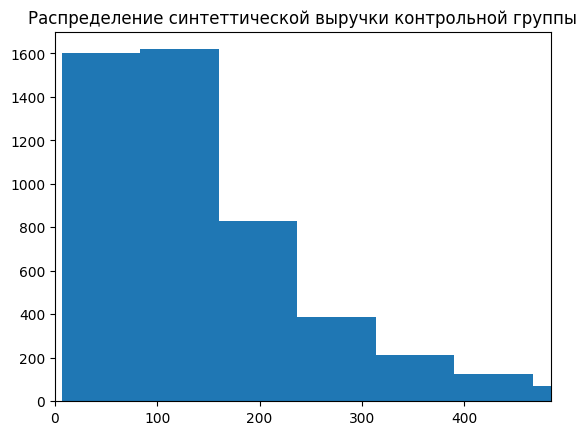

In [ ]:
plt.hist(control_log_Series, bins=25)
plt.title('Распределение синтетической выручки контрольной группы')
plt.xlim(0, 485)

(0.0, 485.0)

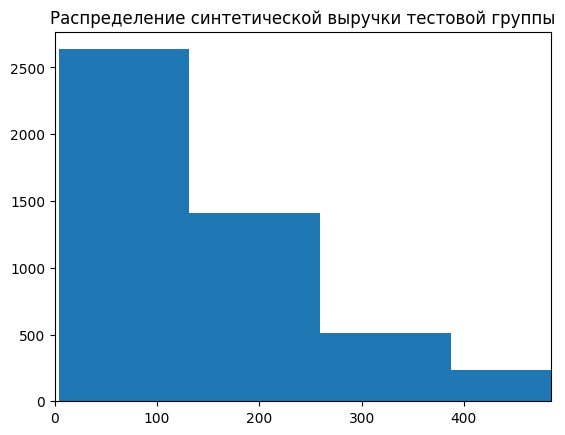

In [ ]:
plt.hist(test_log_Series, bins=25)
plt.title('Распределение синтетической выручки тестовой группы')
plt.xlim(0, 485)

#### t-тест Уэлча

Используем t-тест с `usevar='unequal'` (Уэлч): он не предполагает равенства дисперсий в группах. При больших выборках он корректен и для скошенных распределений благодаря ЦПТ.

In [ ]:
 from statsmodels.stats.weightstats import ttest_ind
 t_stat, p_value, df = ttest_ind(
     control_log,
     test_log,
     usevar='unequal',
     alternative='two-sided'

 )

In [ ]:
print(f'Значение статистики: {t_stat},\nЗначение p_value: {p_value},\nЗначение степеней свободы: {df}')

Значение статистики: -3.8275357551795124,
Значение p_value: 0.00013022947346499352,
Значение степеней свободы: 9899.685269646727


Получили **p-value ≈ 0,00013 < 0,05**, поэтому нулевую гипотезу о равенстве средних отвергаем. В этой симуляции средняя выручка в тестовой группе статистически значимо выше.

### 6.8. A/A-тест для выручки: оценка шума

1 000 A/A-экспериментов на логнормальных данных: проверим ошибку I рода t-теста и посмотрим, насколько может отличаться разность средних без реального эффекта.

In [ ]:
rng = np.random.default_rng()

p_values_from_a_a_test = []
diff_mean = []
for i in range(1000):
  control = rng.lognormal(mean=4.8, sigma=0.8, size=5000)
  test = rng.lognormal(mean=4.8, sigma=0.8, size=5000)

  p_value = ttest_ind(control, test, usevar='unequal', alternative='two-sided')[1]

  control_mean = np.mean(control)
  test_mean = np.mean(test)

  diff_mean.append(control_mean - test_mean)
  p_values_from_a_a_test.append(p_value)

diff_mean_from_a_a_test = pd.Series(diff_mean)
p_values_from_a_a_test = pd.Series(p_values_from_a_a_test)
alpha = len(p_values_from_a_a_test[p_values_from_a_a_test < 0.05])  / len(p_values_from_a_a_test)
print(f'Ошибка первого рода (доля случаев, когда верная H0 ошибочно отвергается) составляет {alpha * 100: .2f}%')

Ошибка первого рода (доля случаев, когда верная H0 ошибочно отвергается) составляет  5.00%


Text(0.5, 1.0, 'Распределение разности средних для оценки шума в наших данных')

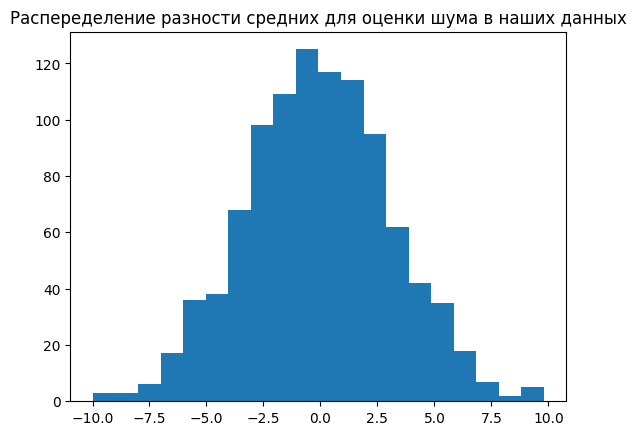

In [ ]:
plt.hist(diff_mean_from_a_a_test, bins=20)
plt.title('Распределение разности средних для оценки шума в наших данных')

In [ ]:
diff_mean_from_a_a_test.describe(percentiles=[0.025, 0.975])

,0
count,1000.000000
mean,-0.081695
std,3.182638
min,-9.979568
2.5%,-6.281788
50%,-0.110360
97.5%,6.110858
max,9.804246


В симуляции доля ошибок первого рода составила около 5%, что соответствует выбранному уровню значимости.

В 95% проведенных A/A-экспериментов разность средних лежит примерно в диапазоне от −6,3 до +6,1. При среднем значении выручки около 165 это примерно ±3,7%. Такой разброс возможен и без заданного эффекта.

### 6.9. A/B-тест для выручки с эффектом

Сдвиг μ на 0,12 соответствует росту средней выручки примерно на e^0,12 − 1 ≈ 12,7%.

In [ ]:
se_dinamic = []

In [ ]:
mdes = [0.01, 0.03, 0.06, 0.09, 0.12]
p_values_from_a_b_test = []
diff_mean_from_a_b_test = []
mde = 0.12
n = 5000
for i in range(1000):
  rng = np.random.default_rng()
  control = rng.lognormal(mean=4.8, sigma=0.8, size=n)
  test = rng.lognormal(mean=4.8 + mde, sigma=0.8, size=n)
  control_mean = np.mean(control)
  test_mean = np.mean(test)
  p_value = ttest_ind(control, test, usevar='unequal', alternative='two-sided')[1]
  p_values_from_a_b_test.append(p_value)
  diff_mean_from_a_b_test.append(control_mean - test_mean)
p_values_from_a_b_test = pd.Series(p_values_from_a_b_test)
se_dinamic.append(np.std(diff_mean_from_a_b_test))
power = len(p_values_from_a_b_test[p_values_from_a_b_test < 0.05]) / len(p_values_from_a_b_test)
print(f'Мощность теста при выборке {n}, минимальном эффекте {mde} составляет {power * 100: .2f}%')

Мощность теста при выборке 5000, минимальном эффекте 0.12 составляет  100.00%


Text(0.5, 1.0, 'Распределение разности средних в симуляциях A/B-теста (на фоне A/A)')

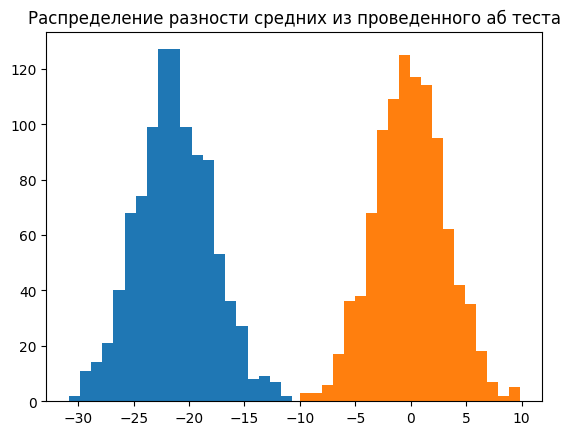

In [ ]:
plt.hist(diff_mean_from_a_b_test, bins=20)
plt.hist(diff_mean_from_a_a_test, bins=20)

plt.title('Распределение разности средних в симуляциях A/B-теста (на фоне A/A)')

В проведенных симуляциях оценка мощности составила **100%**. Распределение разности средних в A/B-тестах имеет центр около −21 и почти не пересекается с распределением A/A около нуля. Эффект такого размера обнаруживался во всех проведенных экспериментах; это не гарантирует результат каждого будущего теста.

In [ ]:
se_dinamic

[np.float64(3.3759665308280544)]

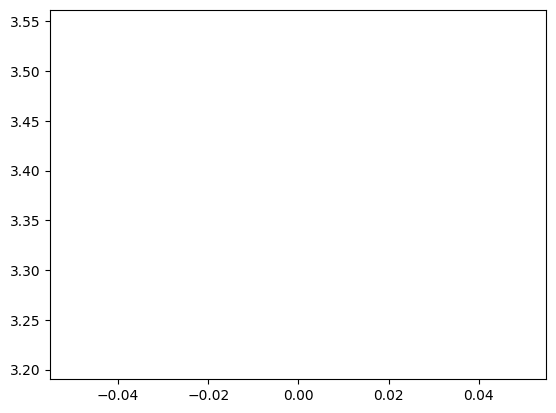

In [ ]:
plt.plot(se_dinamic)

### 6.10. Бутстрап-оценка доверительного интервала

На последней паре выборок из симуляции построим 1 000 бутстрап-выборок (с возвращением) и получим распределение разности средних. Сравним его с «настоящим» распределением, полученным из 1 000 независимых экспериментов.

In [ ]:
boot_mean_diff = []
for count_bootstrap in range(1000):
  boot_control = rng.choice(control, size=len(control), replace=True)
  boot_test = rng.choice(test, size=len(test), replace=True)
  boot_control_mean = np.mean(boot_control)
  boot_test_mean = np.mean(boot_test)
  boot_mean_diff.append(boot_control_mean - boot_test_mean)


(array([  2.,  11.,  14.,  21.,  40.,  68.,  74.,  99., 127., 127.,  99.,
         89.,  87.,  53.,  36.,  27.,   8.,   9.,   7.,   2.]),
 array([-30.85868481, -29.85001697, -28.84134912, -27.83268128,
        -26.82401343, -25.81534558, -24.80667774, -23.79800989,
        -22.78934205, -21.7806742 , -20.77200635, -19.76333851,
        -18.75467066, -17.74600282, -16.73733497, -15.72866712,
        -14.71999928, -13.71133143, -12.70266359, -11.69399574,
        -10.6853279 ]),
 <BarContainer object of 20 artists>)

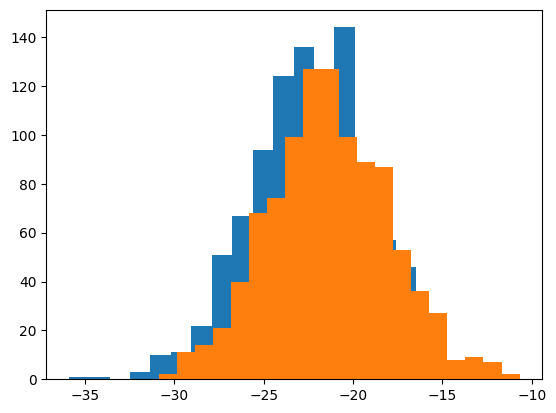

In [ ]:
plt.hist(boot_mean_diff, bins=20)
plt.hist(diff_mean_from_a_b_test, bins=20)


In [ ]:
mean_from_original_diff = np.mean(diff_mean_from_a_b_test)
mean_from_boot_diff = np.mean(boot_mean_diff)
print(f'Средняя разность средних по 1000 экспериментам: {mean_from_original_diff}\nСредняя разность средних по бутстрап-выборкам: {mean_from_boot_diff}')

Средняя разность средних по 1000 экспериментам: -21.31744954492796
Средняя разность средних по бутстрап-выборкам: -22.409209773812684


In [ ]:
pd.Series(boot_mean_diff).quantile([0.025, 0.975])

,0
0.025,-29.056011
0.975,-16.268729


- Бутстрап-распределение по ширине совпадает с распределением из независимых экспериментов, но центрировано на разнице в конкретной выборке (−22,4), а не на истинной (−21,3). Так и должно быть: бутстрап оценивает разброс по одной выборке.

- 95% доверительный интервал разности средних (control − test): [−29,1; −16,3]. Ноль в интервал не входит, различие значимо. Это согласуется с t-тестом.

Бутстрап полезен для метрик, у которых нет простой формулы стандартной ошибки (медиана, перцентили, ratio-метрики).

### 6.11. Проверка SRM (Sample Ratio Mismatch)

SRM означает, что фактическое соотношение размеров групп отличается от запланированного (например, ожидали 50/50, получили 45/55). Это признак ошибки в сплитовании, и выводам такого теста доверять нельзя. Проверим критерием согласия χ².

In [ ]:
N = 10000
groups = rng.choice(['A', 'B'], size=N, p=[0.45, 0.55])

In [ ]:
from scipy.stats import chisquare

In [ ]:
N = 10000
groups = rng.choice(['A', 'B'], size=N, p=[0.5, 0.5])
observed = [np.sum(groups == 'A'), np.sum(groups == 'B')]
expected = [N * 0.5, N * 0.5]
chi2_stat, p_value = chisquare(f_obs=observed,f_exp= expected)
if p_value >= 0.05:
  print(f'H0 не отвергаем: соотношение групп не отличается от 50/50, признаков SRM нет')
else:
  print(f'H0 отвергаем: соотношение групп отличается от 50/50, обнаружен SRM, результатам теста доверять нельзя')

H0 не отвергаем: соотношение групп не отличается от 50/50, признаков SRM нет


При корректном сплите 50/50 p-value ≥ 0,05: SRM не обнаружен.

При перекосе, например 45/55 (такой сплит сгенерирован выше), p-value < 0,05: SRM обнаружен, результатам теста доверять нельзя.

<a id="part7" name="part7"></a>

## **7. Общие выводы**

[↑ К содержанию](#scrollTo=hjqvkl6wdd2D)

<u>Данные Olist</u>

В работе изучили таблицы маркетплейса, объединили данные и посчитали основные метрики. В рассматриваемом периоде 96,9% покупателей сделали один заказ, а Repeat Purchase Rate составил около 3,1%. Когортный анализ также показал низкую долю повторных покупок: в первый месяц она ниже 1%.

Рост выручки в 2017 году в основном связан с ростом числа платящих покупателей. Максимум приходится на ноябрь 2017 года. При сравнении месяцев нужно учитывать неполные данные в начале и конце периода.

Основная часть выручки приходится на SP, RJ и MG. В некоторых удаленных штатах средний чек выше, но причину этого различия нужно изучать отдельно. Также около 11,5% отзывов имеют оценку 1. Можно дополнительно проверить, связаны ли низкие оценки с задержками доставки.

<u>Воронка интернет-магазина</u>

Наибольшая потеря пользователей происходит на шаге view → cart. При анализе динамики отдельно выделился шаг cart → checkout: на mobile конверсия снизилась с 61,5% до 51,0%. Наиболее сильное снижение наблюдается в рекламном канале — с 60,2% до 41,7%.

Чтобы разобраться в причинах, нужно дополнительно посмотреть версии приложения, устройства и рекламные кампании. Данные этой воронки рассматриваются отдельно от данных Olist.

<u>Статистические тесты</u>

На синтетических данных рассмотрели A/A- и A/B-тесты для конверсии и выручки. Проверили частоту ошибок первого рода, зависимость мощности от размера выборки и эффекта, сравнили симуляции с аналитическим расчетом. Также построили бутстрап-интервал и рассмотрели проверку SRM.

*Возможное продолжение работы:* анализ сроков доставки, RFM-сегментация покупателей и проверка гипотез о повторных покупках. Для раздела с экспериментами можно дополнительно изучить CUPED и поправки на множественные сравнения.